# Práctica I — Aprendizaje Estadístico (2026/2027)

## Análisis de salud cardiometabólica con NHANES

#### Hecho por María García Miñarro y Mercedes López Caballero

**Dataset:** `data/nhanes_cardiometabolic_clean.csv` — National Health and Nutrition Examination Survey (CDC, EE. UU.).

**Estructura del trabajo:**

1. Selección del conjunto de datos
2. Exploración de los datos
3. Regresión lineal (simple y múltiple)
4. Selección y regularización: Ridge y Lasso
5. Análisis mediante PCA (y extensión PCR/PLS)
6. Regresión logística
7. Una única base de datos
8. Conclusiones

Se usa **una única base de datos**, ya que sus características permiten plantear razonablemente todos los problemas (regresión, regularización, reducción de dimensión y clasificación binaria).

> Este trabajo usa datos de salud de unas 10.700 personas (encuesta NHANES de EE. UU.) para contestar dos preguntas:
>
> 1. **Predecir un número** — ¿cuánto medirá la presión arterial de una persona? → **regresión**.
> 2. **Predecir un sí/no** — ¿esta persona tiene hipertensión? → **clasificación** (regresión logística).
>
> Para ello "enseñamos" a un modelo con una parte de los datos (**train**) y comprobamos si acierta con otra parte que no ha visto (**test**). 

## 1. Selección del conjunto de datos

Para esta práctica hemos elegido trabajar con datos de **NHANES (National Health and Nutrition Examination Survey)**, un estudio realizado por el *CDC (Centers for Disease Control and prevention)* de Estados Unidos.

Este estudio recoge información sobre la salud y los hábitos de vida de la población estadounidense mediante cuestionarios, exploraciones físicas y análisis de laboratorio. Su objetivo es conocer el estado de salud de la población y estudiar posibles relaciones entre distintas características y enfermedades.

Los datos originales están disponibles públicamente en la [página oficial de NHANES](https://wwwn.cdc.gov/nchs/nhanes/).

En nuestro caso, utilizamos un conjunto de datos consolidado a partir de NHANES, generado mediante el script `get_data.py`. Este archivo, llamado `nhanes_cardiometabolic_clean.csv`, contiene información de **10.739 participantes de 20 años o más**, recogida en **73 columnas**.

Nos hemos centrado en la **salud cardiometabólica**, es decir, en variables relacionadas con el funcionamiento del sistema cardiovascular y el metabolismo. Entre ellas encontramos la presión arterial, el índice de masa corporal (IMC), el colesterol, la glucosa y otros indicadores obtenidos mediante análisis de sangre.

Hemos seleccionado este conjunto de datos principalmente por tres motivos:

- **Permite plantear problemas de regresión y clasificación.** Por ejemplo, podemos intentar predecir la presión arterial sistólica (`sbp`), que es una variable numérica, o estudiar si una persona tiene un diagnóstico de hipertensión (`hypertension_dx`), que es una variable binaria.
- **Contiene numerosas variables que pueden estar relacionadas entre sí.** Por ejemplo, distintos indicadores sanguíneos pueden aportar información similar. Esto resulta interesante para estudiar técnicas como Ridge, Lasso y PCA.
- **Incluye información de diferentes tipos.** Tenemos variables cuantitativas, como la edad o el colesterol, y cualitativas, como el sexo o determinados diagnósticos.

Por tanto, consideramos que este conjunto de datos es adecuado porque nos permite aplicar todas las técnicas solicitadas en la práctica **sin necesidad de utilizar diferentes bases de datos para cada apartado**.

## 2. Exploración de los datos

Antes de empezar a aplicar los modelos, vamos a explorar un poco nuestro conjunto de datos para entender mejor con qué estamos trabajando.

Primero veremos cómo está organizado, qué variables contiene y de qué tipo son. Después analizaremos algunas de sus distribuciones y relaciones, y comprobaremos si hay valores ausentes o características que debamos tener en cuenta antes de construir los modelos.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import seaborn as sns
import statsmodels.api as sm

from scipy.stats import skew

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.cross_decomposition import PLSRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, roc_auc_score, roc_curve)

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (10, 6)
sns.set_theme(style="whitegrid")

In [3]:
df = pd.read_csv("nhanes_cardiometabolic_clean.csv")
print("Número de observaciones:", df.shape[0])
print("Número de variables:", df.shape[1])
df.head()

Número de observaciones: 10739
Número de variables: 73


,seqn,cycle,psu,strata,wt_mec,wt_fasting,fasting_subsample,age,sex,race_eth,...,baso_pct,rbc,hemoglobin,hematocrit,mcv,mch,mchc,rdw,platelets,mpv
0,83732,2015-2016,1,125,67814.753703,NaN,False,62,male,nh_white,...,0.5,4.93,15.2,44.7,90.8,30.8,34.0,13.9,181.0,8.3
1,83733,2015-2016,1,125,12641.212964,27361.171665,True,53,male,nh_white,...,1.8,4.89,17.5,49.7,101.8,35.8,35.1,13.4,170.0,9.6
2,83734,2015-2016,1,131,6287.919409,12735.546850,True,78,male,nh_white,...,0.9,4.18,12.4,37.9,90.8,29.6,32.6,14.7,223.0,9.0
3,83735,2015-2016,1,131,51039.317254,NaN,False,56,female,nh_white,...,0.9,4.54,12.8,40.1,88.3,28.2,31.9,13.1,280.0,9.1
4,83736,2015-2016,2,126,9117.368109,19089.755435,True,42,female,nh_black,...,0.2,4.16,12.1,36.5,87.8,29.1,33.2,12.3,275.0,7.7


### Estructura del conjunto de datos

Al cargar nuestro dataset, vemos que está formado por **10.739 filas y 73 columnas**.

Cada fila corresponde a una persona que ha participado en el estudio NHANES, mientras que las columnas representan las distintas características o mediciones recogidas de esa persona: edad, sexo, peso, presión arterial, resultados de análisis de sangre, etc.

Por ejemplo, en las primeras cinco filas que mostramos podemos ver que el primer participante es un hombre de 62 años. También aparecen otras columnas como `seqn`, que identifica a cada participante, o `cycle`, que indica el periodo del estudio al que pertenece.

Además de las variables relacionadas directamente con la salud, encontramos otras que tienen que ver con cómo se ha realizado el estudio. Es el caso de `wt_mec`, `wt_fasting` o `fasting_subsample`. Esta última nos indica si una persona pertenece a la submuestra en ayunas, que explicaremos un poco más adelante.

Por último, hay que tener en cuenta que **no todas las columnas se utilizarán en los modelos**. Algunas simplemente identifican a los participantes o describen el diseño del estudio, mientras que otras nos servirán para realizar las predicciones y los análisis posteriores.

### Descripción de las variables

Como tenemos bastantes variables, las hemos agrupado según el tipo de información que recogen. Así resulta más sencillo hacerse una idea de qué datos tenemos disponibles.

Los nombres de las columnas están adaptados a partir de los códigos originales del CDC. Algunos son bastante intuitivos, como `age` (edad) o `weight` (peso), mientras que otros son abreviaturas de términos médicos o de laboratorio.

En la siguiente tabla mostramos los distintos grupos de variables y las columnas que pertenecen a cada uno.

| Grupo | Columnas |
|---|---|
| Diseño muestral | `seqn`, `cycle`, `psu`, `strata`, `wt_mec`, `wt_fasting`, `fasting_subsample` |
| Demografía | `age`, `sex`, `race_eth`, `education`, `income_poverty_ratio` |
| Exploración física | `sbp`, `dbp` (medias), `sbp1`, `dbp1`, `pulse`, `weight`, `height`, `bmi`, `waist` |
| Cuestionarios | `smoking`, `diabetes_dx`, `hypertension_dx`, `bp_meds`, `chol_meds` |
| Lípidos y glucosa | `total_chol`, `hdl`, `ldl`, `triglycerides`, `glucose_fasting`, `insulin`, `hba1c` |
| Inflamación | `hs_crp` |
| Hígado | `alt`, `ast`, `alp`, `ggt`, `ldh`, `bilirubin`, `albumin`, `total_protein`, `globulin` |
| Riñón | `creatinine`, `bun`, `uric_acid` |
| Electrolitos/minerales | `sodium`, `potassium`, `chloride`, `bicarbonate`, `calcium`, `phosphorus`, `iron`, `osmolality` |
| Bioquímica sin ayuno | `glucose_serum`, `chol_serum`, `trig_serum`, `cpk` |
| Hemograma | `wbc`, `lymph_pct`, `mono_pct`, `neut_pct`, `eos_pct`, `baso_pct`, `rbc`, `hemoglobin`, `hematocrit`, `mcv`, `mch`, `mchc`, `rdw`, `platelets`, `mpv` |

**Submuestra en ayunas:** En NHANES, algunas pruebas de laboratorio requieren que los participantes hayan pasado un periodo de tiempo sin comer. Por ello, determinadas mediciones, como el colesterol LDL, los triglicéridos, la glucosa en ayunas y la insulina, solo se realizan en una parte de los participantes, principalmente durante las sesiones de mañana.

En nuestro conjunto de datos tenemos **10.739 observaciones**, de las cuales **4.565 pertenecen a la submuestra en ayunas (42,5 %)**. Esto explica que dichas variables presenten un porcentaje elevado de valores ausentes, cercano al 55 %.

Para evitar perder tantas observaciones al trabajar únicamente con registros completos, hemos decidido no incluir estas variables en algunos de los modelos. Sin embargo, sí las tendremos en cuenta en determinados análisis exploratorios, ya que también pueden aportar información interesante.

### Variables cuantitativas y cualitativas

Una vez que sabemos qué información contiene nuestro dataset, vamos a distinguir entre las variables **cuantitativas** y **cualitativas**, ya que no todas se pueden analizar de la misma manera.

- **Cuantitativas:** representan cantidades que podemos medir, como la edad, el peso o la presión arterial.
- **Cualitativas:** representan categorías, como el sexo, si una persona fuma o si tiene diagnosticada hipertensión.

Hay que tener en cuenta que **una variable no es cuantitativa simplemente por estar almacenada como un número**. Por ejemplo, `seqn` identifica a los participantes y `psu` y `strata` hacen referencia al diseño del estudio, por lo que no las consideraremos medidas cuantitativas.

Además, tenemos `fasting_subsample`, que toma los valores `True` o `False` para indicar si una persona pertenece a la submuestra en ayunas. Aunque pandas la guarda como una variable booleana, desde el punto de vista estadístico es cualitativa.

Vamos a separar las variables teniendo en cuenta estas diferencias.

In [5]:
# Variables relacionadas con el diseño del estudio
design_vars = ["seqn", "psu", "strata", "wt_mec", "wt_fasting"]

# Variables cualitativas (incluimos las booleanas)
categorical = df.select_dtypes(
    include=["object", "bool"]
).columns.tolist()

# Variables cuantitativas, excluyendo identificadores y diseño muestral
quantitative = [
    col for col in df.select_dtypes(include=[np.number]).columns
    if col not in design_vars
]

print("Variables de diseño:", len(design_vars), design_vars)
print()
print("Variables cualitativas:", len(categorical), categorical)
print()
print("Variables cuantitativas:", len(quantitative))
print("Primeras 20:", quantitative[:20])

Variables de diseño: 5 ['seqn', 'psu', 'strata', 'wt_mec', 'wt_fasting']

Variables cualitativas: 10 ['cycle', 'fasting_subsample', 'sex', 'race_eth', 'education', 'smoking', 'diabetes_dx', 'hypertension_dx', 'bp_meds', 'chol_meds']

Variables cuantitativas: 58
Primeras 20: ['age', 'income_poverty_ratio', 'sbp', 'sbp1', 'dbp', 'dbp1', 'pulse', 'weight', 'height', 'bmi', 'waist', 'total_chol', 'hdl', 'ldl', 'triglycerides', 'glucose_fasting', 'insulin', 'hba1c', 'hs_crp', 'albumin']


Como vemos, la mayoría de nuestras variables son cuantitativas, algo que nos viene bastante bien para esta práctica, ya que técnicas como la regresión lineal, Ridge, Lasso o PCA trabajan principalmente con datos numéricos.

También tenemos variables cualitativas que nos permiten estudiar otras características de los participantes, como sus hábitos o diagnósticos médicos.

Por último, hemos separado las variables relacionadas con el diseño de NHANES para no confundirlas con las mediciones que utilizaremos en los análisis.

### Resumen estadístico

Ahora que tenemos identificados los distintos tipos de variables, vamos a ver algunos de sus estadísticos principales.

Como tenemos bastantes columnas, hemos seleccionado ocho relacionadas con la edad, las medidas corporales, la presión arterial y algunos indicadores sanguíneos. Así podemos hacernos una idea general de cómo son nuestros datos sin tener que revisar las 73 variables una por una.

Para ello utilizamos `describe()`, que nos permite obtener la media, la desviación típica, los valores mínimos y máximos y los cuartiles de cada variable.

In [6]:
# Resumen numérico de algunas variables relevantes
df[["age", "bmi", "sbp", "dbp", "total_chol", "hdl", "hba1c", "hs_crp"]].describe().round(2)

,age,bmi,sbp,dbp,total_chol,hdl,hba1c,hs_crp
count,10739.00,10581.00,10314.00,10287.00,10094.00,10094.00,10219.00,10042.00
mean,50.42,29.69,126.28,71.49,189.25,53.75,5.86,4.27
std,17.71,7.24,19.26,11.87,41.51,16.73,1.14,8.25
min,20.00,14.20,72.70,8.00,76.00,6.00,3.80,0.08
25%,35.00,24.70,112.70,64.00,161.00,42.00,5.30,0.83
50%,51.00,28.50,123.30,71.30,186.00,51.00,5.60,2.00
75%,65.00,33.40,136.00,78.70,214.00,63.00,6.00,4.60
max,80.00,86.20,238.00,138.70,545.00,226.00,17.00,188.50


A partir de esta tabla podemos sacar algunas conclusiones sobre nuestro conjunto de datos:

- **Edad:** los participantes tienen una media de unos 50 años, aunque encontramos personas desde los 20 hasta los 80. Hay que tener en cuenta que NHANES agrupa a los participantes de 80 años o más en esta última edad.
- **IMC (`bmi`):** la media es de 29,69, mientras que la mediana es algo menor (28,50). Esto nos indica que hay algunos participantes con valores bastante altos que hacen subir la media.
- **Presión arterial (`sbp` y `dbp`):** las medias son de 126,28 y 71,49 mmHg, respectivamente. Sin embargo, encontramos valores bastante alejados de estas medias, especialmente en la presión sistólica, que llega hasta los 238 mmHg.
- **Colesterol total (`total_chol`):** tiene una media de 189,25 mg/dL, pero alcanza valores de hasta 545 mg/dL, por lo que también parece haber algunas observaciones bastante elevadas.
- **Proteína C reactiva (`hs_crp`):** es uno de los casos más llamativos. Su media es de 4,27, pero la mediana es de solo 2 y el máximo alcanza 188,50. Esta diferencia nos hace pensar que su distribución está bastante desplazada hacia la derecha, con unos pocos valores muy elevados.

Además, si nos fijamos en la fila `count`, vemos que no todas las variables tienen el mismo número de observaciones. Por ejemplo, tenemos la edad de los 10.739 participantes, pero solo disponemos de 10.314 mediciones de presión sistólica. Esto nos indica que **hay valores ausentes**, algo que analizaremos con más detalle posteriormente.

En general, este primer resumen nos permite conocer mejor las características de los participantes y detectar algunas variables cuya distribución puede ser interesante estudiar mediante gráficos.

### Visualizaciones relevantes

Una vez que tenemos una idea general de nuestros datos, vamos a representarlos gráficamente para ver algunas características que no siempre se aprecian en las tablas.

Empezaremos viendo cómo se distribuyen algunas variables, después compararemos la presión arterial entre distintos grupos de participantes y, por último, estudiaremos las relaciones entre varios indicadores de salud.

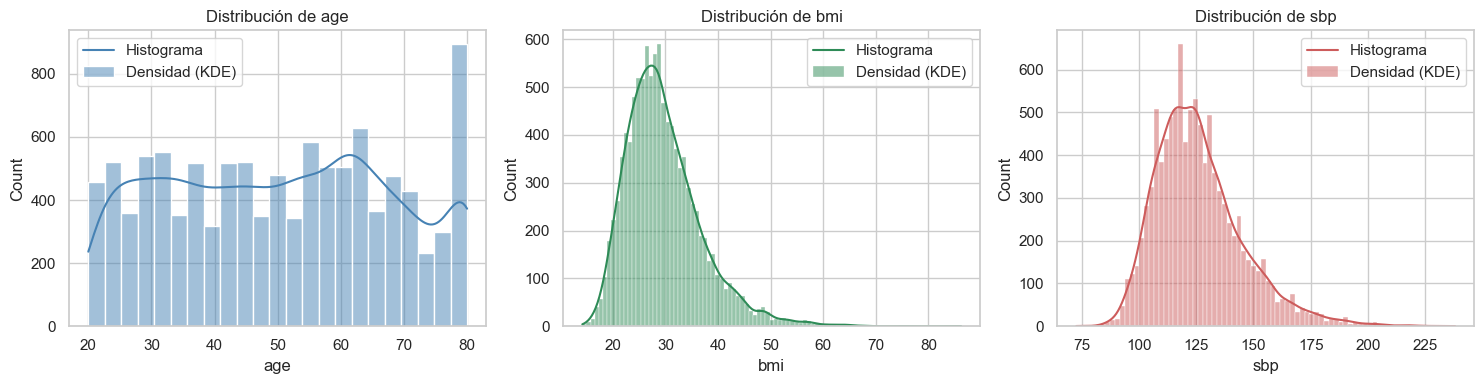

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, var, color in zip(axes, ["age", "bmi", "sbp"], ["steelblue", "seagreen", "indianred"]):
    sns.histplot(data=df, x=var, kde=True, color=color, ax=ax)
    ax.set_title(f"Distribución de {var}")
    ax.legend(["Histograma", "Densidad (KDE)"])
plt.tight_layout()
plt.show()

En estos histogramas podemos ver cómo se distribuyen la edad, el índice de masa corporal (IMC) y la presión arterial sistólica de los participantes.

Cada barra representa el número de personas que se encuentran dentro de un determinado intervalo de valores. Además, hemos añadido una curva de densidad (KDE), que nos ayuda a ver de forma más clara dónde se concentran los datos.

Si nos fijamos en cada variable:

- **Edad (`age`):** los participantes tienen entre 20 y 80 años, con una distribución bastante repartida. Sin embargo, vemos un pico bastante llamativo en los 80 años. Esto se debe a que NHANES agrupa a todas las personas de 80 años o más en esa categoría, por lo que no significa que haya necesariamente muchísimas personas con exactamente 80 años.
- **IMC (`bmi`):** vemos que la mayoría de los participantes se concentra alrededor de valores de 25-30, aunque también encontramos personas con un IMC bastante más elevado. Esto hace que la distribución tenga una cola hacia la derecha, algo que ya podíamos intuir al ver que la media era superior a la mediana.
- **Presión arterial sistólica (`sbp`):** presenta una distribución con forma aproximadamente de campana, concentrada alrededor de los 120-130 mmHg. Sin embargo, también encontramos una cola hacia valores más altos, que corresponde a participantes con mediciones de presión arterial elevadas.

En general, estos gráficos nos permiten comprobar que las variables no siguen todas la misma distribución. Algunas son relativamente simétricas, mientras que otras presentan valores elevados que hacen que se desplacen hacia la derecha.

Esto es interesante porque, cuando construyamos los modelos, tendremos que tener en cuenta las características de las variables con las que estamos trabajando.

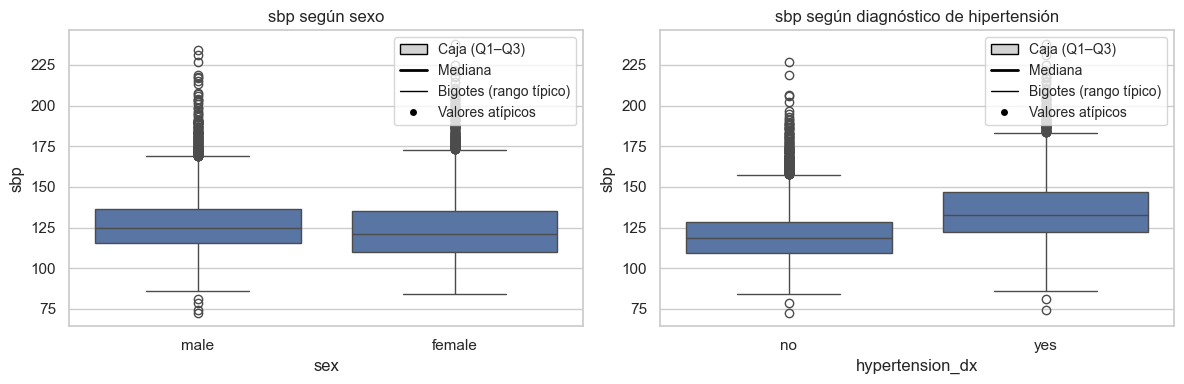

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="sex", y="sbp", ax=axes[0])
axes[0].set_title("sbp según sexo")
sns.boxplot(data=df, x="hypertension_dx", y="sbp", ax=axes[1])
axes[1].set_title("sbp según diagnóstico de hipertensión")

# Leyenda: qué representa cada parte del diagrama de caja
box_legend = [
    Patch(facecolor="lightgrey", edgecolor="black", label="Caja (Q1–Q3)"),
    Line2D([0], [0], color="black", lw=2, label="Mediana"),
    Line2D([0], [0], color="black", lw=1, label="Bigotes (rango típico)"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="black",
           markersize=6, label="Valores atípicos"),
]
axes[0].legend(handles=box_legend, fontsize="small", loc="upper right")
axes[1].legend(handles=box_legend, fontsize="small", loc="upper right")
plt.tight_layout()
plt.show()

En estos gráficos podemos ver cómo cambia la distribución de la presión arterial sistólica entre los distintos grupos.

Para interpretarlos, hay que tener en cuenta que la línea que aparece dentro de cada caja representa la **mediana**, mientras que los extremos de la caja corresponden al primer y tercer cuartil (Q1 y Q3). Los bigotes muestran el rango de valores que no se consideran atípicos según el criterio del gráfico, y los puntos que aparecen fuera representan posibles valores atípicos.

Si nos fijamos en los resultados:

- **Presión arterial según sexo (izquierda):** los hombres presentan una mediana ligeramente superior a la de las mujeres, aproximadamente 124,7 frente a 121,3 mmHg. Sin embargo, las distribuciones se solapan bastante, por lo que no parece que el sexo, por sí solo, permita explicar las diferencias de presión arterial entre los participantes.

- **Presión arterial según diagnóstico de hipertensión (derecha):** aquí sí encontramos una diferencia más clara. Las personas diagnosticadas de hipertensión tienen una mediana de aproximadamente 132,7 mmHg, frente a los 118,7 mmHg de quienes no tienen ese diagnóstico. Esto tiene sentido, ya que la presión arterial está directamente relacionada con la hipertensión. Aun así, las distribuciones también se solapan: tener una medición elevada no implica necesariamente contar con un diagnóstico, y una persona diagnosticada puede presentar valores más bajos, por ejemplo, si sigue un tratamiento.

También encontramos valores atípicos en los distintos grupos, especialmente hacia presiones sistólicas elevadas. Esto no significa necesariamente que sean errores en los datos, sino que hay participantes con mediciones bastante alejadas de las habituales.

En general, estos gráficos nos muestran que **la presión arterial presenta diferencias entre grupos, especialmente según el diagnóstico de hipertensión**, aunque no podemos concluir que estas relaciones sean causales únicamente a partir de estas comparaciones.

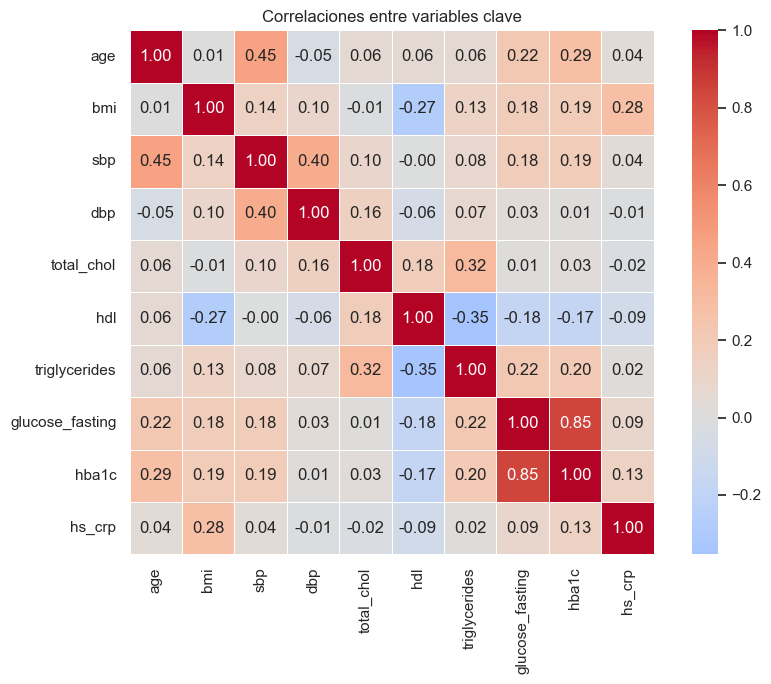

In [9]:
# Correlación entre biomarcadores clave
key = ["age", "bmi", "sbp", "dbp", "total_chol", "hdl", "triglycerides",
       "glucose_fasting", "hba1c", "hs_crp"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[key].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5)
plt.title("Correlaciones entre variables clave")
plt.tight_layout()
plt.show()

En esta matriz podemos ver cómo se relacionan entre sí algunas de las variables de nuestro dataset.

Cada casilla representa la **correlación entre dos variables**, con valores que van de -1 a 1:

- **Valores cercanos a 1 (rojo):** cuando una variable aumenta, la otra tiende a aumentar también.
- **Valores cercanos a -1 (azul):** cuando una variable aumenta, la otra tiende a disminuir.
- **Valores cercanos a 0 (blanco):** no parece existir una relación lineal clara entre ambas variables.

Además, cuanto más intenso es el color, más fuerte es la correlación. La diagonal aparece en rojo porque cada variable tiene una correlación de 1 consigo misma.

Si nos fijamos en los resultados, encontramos algunas relaciones interesantes:

- **Glucosa en ayunas (`glucose_fasting`) y hemoglobina glicosilada (`hba1c`):** presentan una correlación positiva bastante fuerte (r ≈ 0,85). Tiene sentido, ya que ambas están relacionadas con los niveles de glucosa en sangre, aunque miden aspectos diferentes.
- **Edad (`age`) y presión sistólica (`sbp`):** tienen una correlación positiva de aproximadamente 0,45. Esto nos indica que, en general, las personas de mayor edad tienden a presentar una presión sistólica más elevada.
- **Presión sistólica (`sbp`) y diastólica (`dbp`):** también están relacionadas positivamente (r ≈ 0,40), aunque no de forma perfecta, ya que representan dos mediciones diferentes de la presión arterial.
- **Colesterol HDL (`hdl`) y triglicéridos (`triglycerides`):** muestran una correlación negativa (r ≈ -0,35). Es decir, las personas con niveles más elevados de triglicéridos tienden a presentar niveles más bajos de colesterol HDL.

En general, esta matriz nos permite observar que **algunas variables contienen información relacionada**, especialmente determinados indicadores sanguíneos.

Esto será importante más adelante, cuando utilicemos **Ridge, Lasso y PCA**, ya que estas técnicas resultan especialmente interesantes cuando tenemos varias variables predictoras correlacionadas entre sí.

Por último, hay que recordar que una correlación no implica causalidad. Que dos variables estén relacionadas no significa necesariamente que una sea la causa de la otra.

### Valores ausentes

In [8]:
missing = df.isna().mean().sort_values(ascending=False)
print("Variables con mayor proporción de ausentes (%):")
print((missing.head(15) * 100).round(1).to_string())

print()
print("Observaciones sin ningún valor ausente:", df.dropna().shape[0], "de", df.shape[0])

Variables con mayor proporción de ausentes (%):
chol_meds               71.9
ldl                     57.2
triglycerides           56.7
insulin                 55.3
glucose_fasting         54.5
wt_fasting              52.1
income_poverty_ratio    11.8
dbp1                     9.2
sbp1                     8.6
ldh                      7.3
hs_crp                   6.5
ast                      6.4
waist                    6.4
cpk                      6.4
globulin                 6.3

Observaciones sin ningún valor ausente: 989 de 10739


### Discusión de los valores ausentes

Como podemos ver, no tenemos información de todas las variables para todos los participantes. Algunas apenas presentan valores ausentes, mientras que otras tienen más de la mitad de sus registros vacíos.

Hay varios casos que merece la pena comentar:

- **Submuestra en ayunas:** las variables `ldl`, `triglycerides`, `glucose_fasting` e `insulin` presentan entre un 54 % y un 57 % de valores ausentes. Como explicamos anteriormente, estas pruebas solo se realizan en una parte de los participantes, por lo que no se trata simplemente de datos que se hayan perdido, sino de valores ausentes relacionados con el diseño del estudio.
- **Medicación para el colesterol (`chol_meds`):** es la variable con más valores ausentes, concretamente un 71,9 %. Esto nos indica que tenemos muy poca información disponible en comparación con otras columnas. No obstante, habría que revisar cómo se ha construido esta variable para saber si los valores ausentes corresponden a respuestas no recogidas, preguntas que no se hicieron a determinados participantes u otros motivos.
- **Nivel de ingresos (`income_poverty_ratio`):** presenta un 11,8 % de valores ausentes. Aunque es un porcentaje bastante menor, también debemos tenerlo en cuenta si queremos utilizar esta variable en algún análisis.
- **Lecturas de presión arterial (`sbp1` y `dbp1`):** tienen aproximadamente un 9 % de valores ausentes, por lo que tampoco disponemos de estas mediciones para todos los participantes.

De hecho, si exigimos que una persona tenga información en las 73 columnas, **solo nos quedan 989 observaciones completas de las 10.739 iniciales**. Esto supondría perder más del 90 % de los datos.

Por eso, en lugar de eliminar directamente todas las filas que tengan algún valor ausente, utilizaremos `dropna()` únicamente sobre las columnas que necesitemos en cada modelo. Así evitamos descartar participantes por no tener información en variables que ni siquiera vamos a utilizar.

Además, en algunos modelos no incluiremos las variables de la submuestra en ayunas para poder trabajar con un mayor número de observaciones.

Esta estrategia nos permite conservar más datos, aunque tiene una limitación: **al trabajar únicamente con los casos completos de cada modelo, la muestra puede cambiar y no tiene por qué representar exactamente a todos los participantes originales**. Tampoco estamos aplicando técnicas de imputación para recuperar los valores ausentes, algo que se podría estudiar en un análisis más avanzado.

### Anomalías y aspectos relevantes

In [10]:
# 1) globulin es una combinación lineal exacta de total_protein y albumin
g = df[["globulin", "total_protein", "albumin"]].dropna()
print("globulin == total_protein - albumin :",
      np.allclose(g["globulin"], g["total_protein"] - g["albumin"]))

# 2) Asimetría de los biomarcadores
num_vars = ["age", "bmi", "sbp", "total_chol", "hdl", "triglycerides", "insulin",
            "hs_crp", "ggt", "alt", "cpk", "glucose_fasting"]
sk = pd.Series({c: skew(df[c].dropna()) for c in num_vars}).sort_values(ascending=False)
print()
print("Asimetría (skewness) de variables seleccionadas:")
print(sk.round(2).to_string())

globulin == total_protein - albumin : True

Asimetría (skewness) de variables seleccionadas:
cpk                20.58
ggt                12.66
triglycerides       9.09
insulin             8.51
hs_crp              8.22
alt                 4.58
glucose_fasting     3.87
hdl                 1.22
bmi                 1.20
sbp                 1.03
total_chol          0.73
age                 0.02


Además de los valores ausentes, hemos encontrado algunas características de nuestros datos que merece la pena tener en cuenta antes de construir los modelos.

**1. Variables que contienen información repetida**

Lo primero que hemos comprobado es que la variable `globulin` se obtiene directamente restando `albumin` a `total_protein`:

`globulin = total_protein - albumin`

Como vemos en el resultado (`True`), esta relación se cumple en nuestros datos.

Esto significa que, si incluimos las tres variables en una regresión lineal, estaremos introduciendo información redundante. Además, provocaría un problema de dependencia lineal exacta entre los predictores, por lo que hemos decidido no incluir `globulin` junto a las otras dos en los modelos posteriores.

**2. Variables con distribuciones muy asimétricas**

También hemos calculado la asimetría (*skewness*) de algunos indicadores para comprobar si sus valores se distribuyen de forma equilibrada o si se concentran más hacia un lado.

Encontramos algunos valores bastante elevados, especialmente en `cpk` (20,58), `ggt` (12,66), `triglycerides` (9,09), `insulin` (8,51) y `hs_crp` (8,22).

Esto significa que la mayoría de los participantes tienen valores relativamente bajos o moderados, pero unos pocos presentan valores mucho más altos, haciendo que la distribución tenga una cola larga hacia la derecha.

Para reducir esta asimetría, más adelante aplicaremos una transformación logarítmica (`log(1+x)`) a algunas de estas variables antes de estandarizarlas. Así reducimos las diferencias de escala provocadas por los valores muy elevados, aunque no significa que estemos eliminando esas observaciones.

**3. Variables muy correlacionadas entre sí**

Como vimos anteriormente, algunas variables de nuestro conjunto de datos están bastante relacionadas. Por ejemplo:

- `total_chol` y `chol_serum`: correlación de aproximadamente 0,99.
- `hemoglobin` y `hematocrit`: correlación de aproximadamente 0,97.
- `sodium` y `osmolality`: correlación de aproximadamente 0,81.
- `ast` y `alt`: correlación de aproximadamente 0,73.

Cuando varias variables predictoras están muy relacionadas hablamos de **multicolinealidad**. Esto puede complicar la interpretación de una regresión lineal, ya que resulta más difícil distinguir qué información está aportando cada variable por separado.

Precisamente por eso nos interesa utilizar técnicas como **Ridge y Lasso**, que permiten regularizar los coeficientes, y **PCA**, que nos ayuda a resumir la información de variables correlacionadas mediante componentes principales.

**4. Influencia de la medicación**

Por último, también debemos tener en cuenta que algunos participantes toman medicamentos para controlar la presión arterial (`bp_meds`) o el colesterol (`chol_meds`).

Esto es importante porque las mediciones que tenemos pueden estar influidas por esos tratamientos. Por ejemplo, una persona diagnosticada de hipertensión puede presentar una presión arterial relativamente baja si está tomando medicación.

Por tanto, tendremos que tenerlo presente al interpretar las relaciones entre las variables, ya que una medición no siempre refleja cómo estaría esa persona sin tratamiento.

## 3. Regresión lineal

Una vez que conocemos un poco mejor nuestros datos, vamos a empezar con los modelos de regresión lineal.

El objetivo de estos modelos es **predecir el valor de una variable numérica a partir de otras variables**. En nuestro caso, queremos estudiar si podemos estimar la presión arterial de una persona utilizando características como su edad, su IMC o sus niveles de colesterol.

Primero analizaremos las relaciones entre estas variables y después construiremos dos modelos: uno de regresión lineal simple, que utiliza un único predictor, y otro de regresión lineal múltiple, que utiliza varios.

Así podremos comprobar si añadir más información realmente nos ayuda a mejorar las predicciones.

### 3.1. Variable respuesta y relación con los predictores

Hemos elegido como **variable respuesta** la presión arterial sistólica (`sbp`), medida en mmHg, ya que es una variable cuantitativa y tenemos información de ella para la mayoría de los participantes.

Las variables que utilizaremos para intentar predecirla se conocen como **predictores** o variables explicativas.

Antes de construir los modelos, vamos a representar gráficamente cómo se relaciona la presión sistólica con tres posibles predictores: la edad (`age`), el IMC (`bmi`) y el colesterol total (`total_chol`).

En cada gráfico aparecerán las observaciones individuales y una recta de regresión que nos permitirá identificar la tendencia general de la relación.

/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: divide by zero encountered in matmul
  return _core_matmul(x1, x2)
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: overflow encountered in matmul
  return _core_matmul(x1, x2)
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: invalid value encountered in matmul
  return _core_matmul(x1, x2)
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: divide by zero encountered in matmul
  return _core_matmul(x1, x2)
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: overflow encountered in matmul
  return _core_matmul(x1, x2)
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/numpy/linalg/_linalg.p

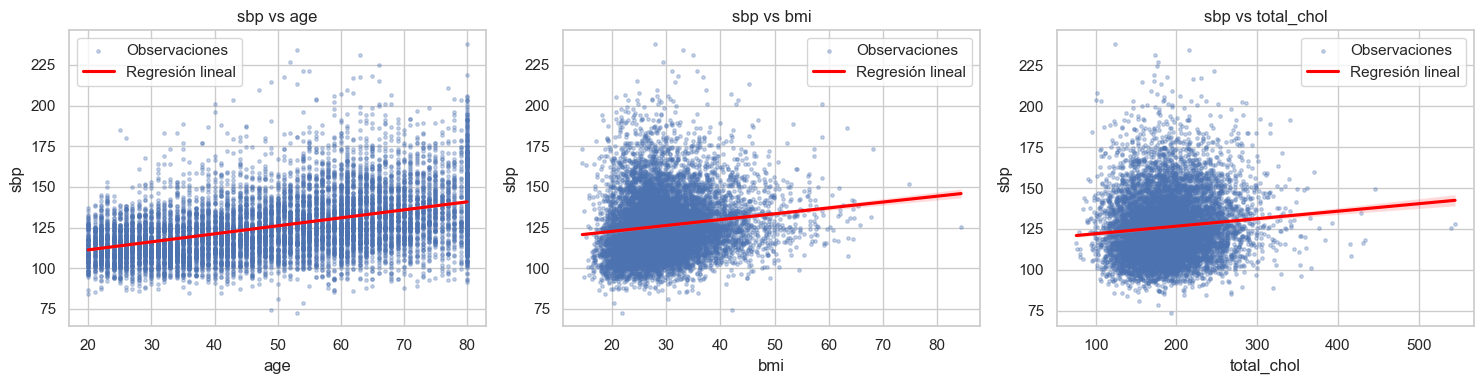

In [11]:
resp = "sbp"
# Relación gráfica de sbp con algunos predictores
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, var in zip(axes, ["age", "bmi", "total_chol"]):
    d = df[[resp, var]].dropna()
    sns.regplot(data=d, x=var, y=resp,
                scatter_kws={"s": 6, "alpha": 0.3}, line_kws={"color": "red"}, ax=ax)
    ax.set_title(f"{resp} vs {var}")
    ax.collections[0].set_label("Observaciones")
    ax.lines[0].set_label("Regresión lineal")
    ax.legend()
plt.tight_layout()
plt.show()

En estos gráficos podemos ver cómo se relaciona la presión arterial sistólica con la edad, el IMC y el colesterol total.

Cada punto representa a un participante, mientras que la línea roja muestra la tendencia general de la relación entre las dos variables.

Si nos fijamos en los resultados:

- **Presión sistólica y edad (`age`):** es donde encontramos la relación más clara. La recta tiene una pendiente positiva, lo que nos indica que, en general, las personas de mayor edad tienden a presentar una presión arterial más elevada. Aunque hay bastante dispersión, la tendencia ascendente se aprecia bien.

- **Presión sistólica e IMC (`bmi`):** también observamos una relación positiva, pero bastante menos marcada. La nube de puntos está más dispersa alrededor de la recta, por lo que el IMC, por sí solo, no parece explicar demasiado bien las diferencias de presión arterial.

- **Presión sistólica y colesterol total (`total_chol`):** en este caso, la recta es prácticamente horizontal. Esto indica que no encontramos una relación lineal clara entre ambas variables, al menos cuando las analizamos por separado.

En general, parece que **la edad es el predictor más relacionado con la presión sistólica de los tres que hemos representado**.

Por eso, vamos a empezar construyendo un modelo de regresión lineal simple utilizando únicamente la edad. Después veremos si añadir otras variables nos permite obtener mejores resultados.

### 3.2. Regresión lineal simple (`sbp ~ age`)

Como hemos visto en los gráficos anteriores, la edad es la variable que presenta una relación lineal más clara con la presión arterial sistólica de las tres que hemos analizado.

Por eso, vamos a empezar construyendo un modelo de **regresión lineal simple**, utilizando únicamente la edad (`age`) para intentar predecir la presión sistólica (`sbp`).

Para ello utilizamos mínimos cuadrados ordinarios (OLS), que busca la recta que mejor se ajusta a nuestros datos minimizando la suma de los errores al cuadrado.

Antes de ajustar el modelo eliminamos las observaciones que no tienen información en alguna de estas dos variables. De esta forma, trabajamos con **10.314 participantes**.

In [12]:
d_simple = df[[resp, "age"]].dropna()
X_s = sm.add_constant(d_simple["age"])
model_simple = sm.OLS(d_simple[resp], X_s).fit()
print(model_simple.summary())

                            OLS Regression Results                            
Dep. Variable:                    sbp   R-squared:                       0.204
Model:                            OLS   Adj. R-squared:                  0.204
Method:                 Least Squares   F-statistic:                     2642.
Date:                Fri, 30 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:39:50   Log-Likelihood:                -43969.
No. Observations:               10314   AIC:                         8.794e+04
Df Residuals:                   10312   BIC:                         8.796e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        101.4229      0.512    197.973      0.0

**Interpretación del modelo simple**

Una vez ajustado el modelo, obtenemos la siguiente ecuación:

$$\widehat{sbp} = 101.42 + 0.492 \cdot age$$

Esta ecuación nos permite estimar la presión arterial sistólica de una persona a partir de su edad. Vamos a ver qué significa cada uno de sus términos:

- **Intercepto (101,42):** representa la presión sistólica que estimaría el modelo para una persona de 0 años. En nuestro caso no tiene una interpretación práctica, ya que estamos trabajando con participantes adultos, pero es necesario para definir la recta.
- **Coeficiente de la edad (0,492):** indica que, por cada año adicional de edad, el modelo estima un aumento medio de aproximadamente 0,49 mmHg en la presión sistólica. Es decir, dos personas que se diferencien en 10 años tendrían una diferencia estimada de unos 4,9 mmHg.
- **Significación estadística:** el coeficiente de la edad tiene un valor p muy pequeño (p < 0,001), lo que indica que encontramos evidencia estadística de una relación lineal positiva entre la edad y la presión sistólica.
- **Coeficiente de determinación (R² = 0,204):** nos indica qué proporción de la variabilidad de la presión arterial consigue explicar nuestro modelo. En este caso, la edad explica aproximadamente el **20,4 %**, mientras que el 79,6 % restante no queda explicado por esta regresión.

Para entender mejor las predicciones, podemos sustituir la edad en la ecuación:

- Una persona de **20 años** tendría una presión sistólica estimada de aproximadamente **111,3 mmHg**.
- Una persona de **80 años** tendría una presión sistólica estimada de aproximadamente **140,8 mmHg**.

Eso sí, estas son estimaciones del modelo, no significa que todas las personas de esas edades tengan esos valores. Dos personas de la misma edad pueden presentar presiones muy diferentes debido a otras características que todavía no estamos considerando.

En general, el modelo confirma lo que ya habíamos observado gráficamente: **la presión sistólica tiende a aumentar con la edad**. Sin embargo, el R² también nos muestra que conocer únicamente la edad no es suficiente para predecir con mucha precisión la presión arterial de una persona.

Por eso, más adelante probaremos a incorporar otras variables para ver si conseguimos mejorar el ajuste

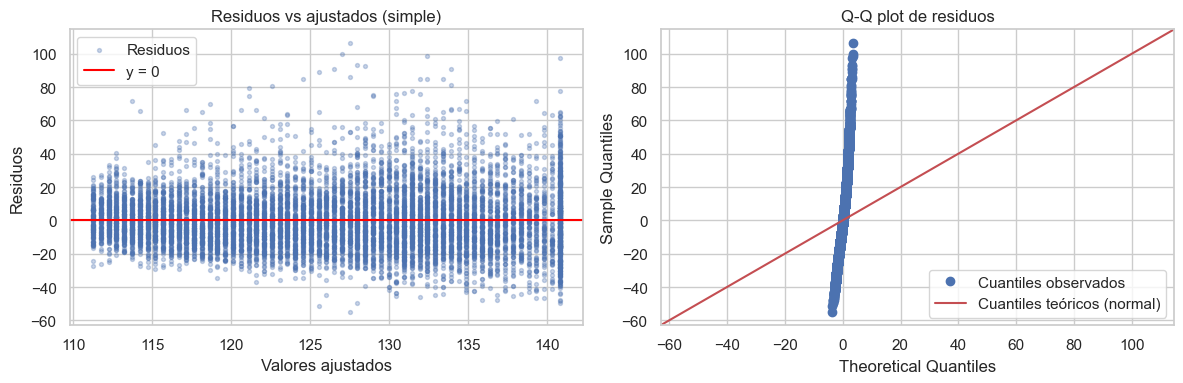

In [13]:
# Residuos del modelo simple
fitted = model_simple.fittedvalues
resid = model_simple.resid
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(fitted, resid, s=8, alpha=0.3, label="Residuos")
axes[0].axhline(0, color="red", label="y = 0")
axes[0].set_xlabel("Valores ajustados"); axes[0].set_ylabel("Residuos")
axes[0].set_title("Residuos vs ajustados (simple)")
axes[0].legend()
sm.qqplot(resid, line="45", ax=axes[1])
axes[1].set_title("Q-Q plot de residuos")
axes[1].legend(["Cuantiles observados", "Cuantiles teóricos (normal)"])
plt.tight_layout()
plt.show()

Además de interpretar los coeficientes y el R², vamos a comprobar cómo se comportan los errores de nuestro modelo.

Los **residuos** son las diferencias entre los valores reales de presión arterial y los que predice la regresión. Por ejemplo, si una persona tiene una presión de 140 mmHg y el modelo predice 130 mmHg, su residuo sería de +10 mmHg.

En los gráficos podemos observar lo siguiente:

- **Residuos frente a valores ajustados (izquierda):** cada punto representa el error cometido en una observación. Lo ideal es que los residuos se distribuyan de manera más o menos aleatoria alrededor de cero, sin patrones claros. En nuestro caso, vemos una dispersión considerable, pero no parece existir una curvatura muy marcada. Esto sugiere que una relación lineal puede ser una primera aproximación razonable, aunque el modelo sigue cometiendo errores importantes en algunas observaciones.

- **Q-Q plot (derecha):** este gráfico compara la distribución de nuestros residuos con una distribución normal. Si siguieran aproximadamente una normal, los puntos se situarían cerca de la diagonal. En nuestro caso, observamos ciertas desviaciones, especialmente en los extremos, lo que indica que los residuos no siguen perfectamente una distribución normal.

En general, estos resultados nos muestran que **la regresión lineal simple permite identificar una tendencia, pero tiene limitaciones a la hora de predecir la presión arterial individual**.

Esto no significa que el modelo no sirva, sino que la edad es solo una de las muchas características que pueden estar relacionadas con la presión arterial.los **residuos** son la diferencia entre la presión real y la predicha (el "error" de cada persona).

- **Izquierda (residuos vs ajustados):** si los puntos se reparten al azar en una banda horizontal alrededor de 0 (sin forma de embudo ni de curva), el modelo es razonable. Aquí se ve una banda más o menos constante.
- **Derecha (Q-Q plot):** compara la distribución de los residuos con una normal. Cuanto más pegados estén los puntos a la diagonal, más "normales" son los residuos (un supuesto habitual). Aquí se separan un poco en los extremos, algo normal con datos reales.


### 3.3. Regresión lineal múltiple

En el modelo anterior hemos utilizado únicamente la edad para predecir la presión arterial sistólica. Aunque hemos encontrado una relación bastante clara, también hemos visto que la edad por sí sola no consigue explicar gran parte de las diferencias entre los participantes.

Por eso, ahora vamos a construir un modelo de **regresión lineal múltiple**, incorporando más variables que podrían estar relacionadas con la presión arterial.

En concreto, hemos seleccionado:

- **Edad (`age`):** porque es la variable con la que hemos encontrado una relación más clara hasta ahora.
- **IMC (`bmi`):** para tener en cuenta las características corporales de los participantes.
- **Colesterol total (`total_chol`) y HDL (`hdl`):** para incorporar algunos indicadores relacionados con la salud cardiovascular.
- **Sexo (`sex`) y tabaquismo (`smoking`):** para comprobar si también encontramos diferencias en la presión arterial según estas características.

No hemos utilizado todas las variables disponibles, sino una selección que nos permite estudiar distintos aspectos de la salud sin construir un modelo excesivamente complicado.

Además, como `sex` y `smoking` son variables cualitativas, las convertimos en variables binarias mediante `get_dummies()`, ya que el modelo necesita trabajar con valores numéricos.

Por último, eliminamos las observaciones que tengan algún valor ausente en las variables seleccionadas. De esta forma, nos quedamos con **9.620 participantes**.

La principal diferencia respecto a la regresión simple es que ahora cada coeficiente representa la relación de una variable con la presión arterial **manteniendo constantes las demás variables del modelo**. Es decir, intentamos distinguir qué aporta cada predictor teniendo en cuenta que los participantes pueden diferenciarse en varias características a la vez.

In [16]:
cols = [resp, "age", "bmi", "total_chol", "hdl", "sex", "smoking"]
d_multi = df[cols].dropna()

# Convertimos las variables categóricas en columnas numéricas (0 y 1)
d_multi = pd.get_dummies(
    d_multi,
    columns=["sex", "smoking"],
    drop_first=True,
    dtype=int
)

y_m = d_multi[resp]
X_m = d_multi.drop(columns=resp)
X_m_const = sm.add_constant(X_m)

model_multi = sm.OLS(y_m, X_m_const).fit()
print(model_multi.summary())

                            OLS Regression Results                            
Dep. Variable:                    sbp   R-squared:                       0.236
Model:                            OLS   Adj. R-squared:                  0.235
Method:                 Least Squares   F-statistic:                     423.5
Date:                Fri, 30 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:41:48   Log-Likelihood:                -40657.
No. Observations:                9620   AIC:                         8.133e+04
Df Residuals:                    9612   BIC:                         8.139e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const             81.8482      1.433     57.

**Interpretación del modelo múltiple**

Una vez ajustado el modelo, obtenemos un **R² de 0,236**, lo que significa que las variables seleccionadas explican aproximadamente el 23,6 % de la variabilidad de la presión sistólica.

Para entender mejor los resultados, vamos a interpretar algunos de los coeficientes:

- **Edad (`age`, +0,488):** por cada año adicional de edad, el modelo estima un aumento medio de aproximadamente 0,49 mmHg en la presión sistólica, manteniendo constantes las demás variables. Además, su coeficiente apenas ha cambiado respecto al modelo simple (0,492), por lo que la relación positiva que habíamos encontrado se mantiene.
- **IMC (`bmi`, +0,394):** por cada unidad adicional de IMC, la presión sistólica estimada aumenta aproximadamente 0,39 mmHg, si el resto de características permanece constante.
- **Colesterol total (`total_chol`, +0,034):** presenta una relación positiva con la presión sistólica, aunque el cambio estimado por cada mg/dL es pequeño. Por ejemplo, una diferencia de 10 mg/dL supondría aproximadamente 0,34 mmHg en la predicción.
- **Colesterol HDL (`hdl`, +0,018):** su coeficiente también es positivo, pero tiene un valor p de 0,113. Por tanto, no encontramos evidencia estadística suficiente para afirmar que exista una relación lineal con la presión sistólica una vez consideradas las demás variables.
- **Sexo (`sex_male`, +3,09):** el modelo estima que los hombres presentan, de media, una presión sistólica unos 3,09 mmHg superior a la de las mujeres con las mismas características consideradas en el modelo.
- **Tabaquismo (`smoking`):** tomando como referencia a los fumadores actuales, los exfumadores presentan una presión sistólica estimada aproximadamente 2,14 mmHg inferior. Para quienes nunca han fumado, la diferencia estimada es de -0,85 mmHg, aunque en este caso el valor p (0,065) no alcanza el nivel habitual de significación del 5 %.

Hay que tener en cuenta que **estos coeficientes representan asociaciones, no relaciones de causa y efecto**. Por ejemplo, que los exfumadores presenten una presión sistólica algo menor en nuestro modelo no significa que haber fumado anteriormente reduzca la presión arterial.

**Comparación con la regresión simple**

Si comparamos ambos modelos, vemos que el R² ha pasado de **0,204 a 0,236**.

Esto significa que, al añadir más variables, conseguimos explicar aproximadamente 3,2 puntos porcentuales adicionales de la variabilidad de la presión sistólica.

Por tanto, el modelo múltiple mejora el ajuste, pero la diferencia tampoco es demasiado grande. Esto nos indica que, aunque las nuevas variables aportan información, **todavía hay muchos factores que nuestro modelo no consigue recoger**.

Además, debemos tener en cuenta que los dos ajustes se han realizado con un número diferente de participantes. Por eso, para comparar su capacidad predictiva de forma más justa, evaluaremos ambos modelos sobre el mismo conjunto de test en el siguiente apartado.

### 3.4 Predicciones para nuevas observaciones

In [17]:
# Nueva observación: mujer, 55 años, IMC 28, colesterol total 200, HDL 55, no fumadora
nueva = pd.DataFrame([{"age": 55, "bmi": 28, "total_chol": 200, "hdl": 55,
                       "sex_male": 0, "smoking_former": 0, "smoking_never": 1}])[X_m.columns]
pred_nueva = model_multi.predict(sm.add_constant(nueva, has_constant="add"))[0]
print(f"Predicción de sbp para la nueva observación: {pred_nueva:.1f} mmHg")

Predicción de sbp para la nueva observación: 126.7 mmHg


Una vez construido nuestro modelo de regresión múltiple, podemos utilizarlo para estimar la presión arterial de una persona a partir de sus características.

Para comprobarlo, hemos creado una persona ficticia con los siguientes datos:

- Mujer de 55 años.
- IMC de 28.
- Colesterol total de 200 mg/dL.
- Colesterol HDL de 55 mg/dL.
- No fumadora.

Al introducir estos valores en nuestro modelo, obtenemos una **presión arterial sistólica estimada de 126,7 mmHg**.

Esto no significa que una persona con estas características tenga necesariamente esa presión arterial. El modelo calcula una estimación basándose en las relaciones que ha aprendido de los datos, pero hay muchos otros factores que pueden influir en la presión real de una persona.

Además, esta predicción se ha realizado con el modelo que habíamos ajustado utilizando todos los casos completos disponibles. Por tanto, sirve para mostrar cómo podemos utilizar la regresión para hacer predicciones, pero todavía no nos dice cómo de bien funcionará con personas que no haya visto antes.

In [18]:
# Evaluación predictiva simple vs múltiple (train/test)
# 💡 Enseñamos con el 80 % (entrenamiento) y comprobamos con el 20 % que el
#    modelo NO ha visto (test). Así medimos si generaliza a gente nueva y no
#    se ha aprendido los datos de memoria.
#    - MSE: error medio de las predicciones (cuanto más bajo, mejor).
#    - R²: proporción de la variación de sbp que explica el modelo.
from sklearn.metrics import mean_squared_error, r2_score

X_tr, X_te, y_tr, y_te = train_test_split(
    X_m_const, y_m, test_size=0.2, random_state=RANDOM_STATE)

ols_simple = sm.OLS(y_tr, X_tr[["const", "age"]]).fit()
ols_multi = sm.OLS(y_tr, X_tr).fit()

for name, model, cols_use in [("Simple", ols_simple, ["const", "age"]),
                              ("Múltiple", ols_multi, X_tr.columns)]:
    pred = model.predict(X_te[cols_use])
    print(f"{name:9s} -> MSE test = {mean_squared_error(y_te, pred):.1f} | "
          f"R² test = {r2_score(y_te, pred):.3f}")

Simple    -> MSE test = 297.3 | R² test = 0.217
Múltiple  -> MSE test = 289.0 | R² test = 0.239


**Comparación de los modelos con datos de test**

Hasta ahora hemos estudiado cómo se ajustan nuestros modelos a los datos disponibles, pero también nos interesa saber si pueden realizar buenas predicciones sobre personas que no se han utilizado para entrenarlos.

Para comprobarlo, hemos dividido los datos en dos grupos:

- **Entrenamiento (80 %):** utilizamos estas observaciones para ajustar los modelos.
- **Test (20 %):** reservamos estas observaciones para evaluar las predicciones, sin utilizarlas durante el entrenamiento.

Además, hemos utilizado la misma división para ambos modelos, de forma que podamos compararlos en igualdad de condiciones.

Para evaluar sus resultados utilizamos dos métricas:

- **MSE (error cuadrático medio):** mide el promedio de los errores al cuadrado entre las predicciones y los valores reales. Cuanto menor sea, mejor. En nuestro caso se expresa en mmHg².
- **R² (coeficiente de determinación):** indica qué proporción de la variabilidad de la presión arterial consigue explicar el modelo. Cuanto mayor sea, mejor, aunque un R² elevado tampoco garantiza que todas las predicciones individuales sean precisas.

Los resultados obtenidos son:

| Modelo | MSE test | R² test |
|---|---:|---:|
| Regresión simple | 297,3 | 0,217 |
| Regresión múltiple | 289,0 | 0,239 |

Como vemos, **el modelo múltiple obtiene resultados ligeramente mejores**: tiene un error cuadrático medio menor y consigue explicar algo más de la variabilidad de la presión arterial.

Sin embargo, la mejora tampoco es demasiado grande. El R² pasa de 0,217 a 0,239, es decir, aumenta 2,2 puntos porcentuales.

Esto nos indica que añadir variables como el IMC, el colesterol, el sexo o el tabaquismo ayuda a mejorar las predicciones, pero no supone un cambio enorme respecto a utilizar únicamente la edad.

En definitiva, **la regresión múltiple funciona algo mejor que la simple**, aunque ambos modelos siguen dejando sin explicar buena parte de las diferencias de presión arterial entre los participantes.

## 4. Selección y regularización: Ridge y Lasso

Hasta ahora hemos construido modelos de regresión lineal utilizando unas pocas variables. Sin embargo, nuestro conjunto de datos contiene muchos más indicadores que podrían ayudarnos a predecir la presión arterial sistólica.

El problema es que, como vimos en la exploración, **algunas de estas variables están muy relacionadas entre sí**. Por ejemplo, el colesterol total y el colesterol en suero presentan una correlación cercana a 0,99.

Cuando utilizamos varios predictores muy correlacionados en una regresión lineal, podemos encontrarnos con un problema de **multicolinealidad**. Esto hace que resulte más difícil distinguir qué información está aportando cada variable y puede provocar que los coeficientes sean inestables, es decir, que cambien bastante ante pequeñas modificaciones de los datos.

Para intentar solucionar este problema vamos a utilizar dos técnicas de regularización:

- **Ridge (L2):** introduce una penalización que hace que los coeficientes se reduzcan, acercándolos a cero. De esta forma, evita que algunos coeficientes tengan valores excesivamente grandes, aunque normalmente no elimina variables.
- **Lasso (L1):** funciona de forma parecida, pero tiene una diferencia importante: puede hacer que algunos coeficientes sean exactamente cero. Esto significa que, además de regularizar, también puede realizar una selección automática de variables.

Ambas técnicas utilizan un parámetro llamado **α (alpha)**, que controla la intensidad de la regularización. Podemos verlo como una especie de freno: cuanto mayor sea α, más penalizamos los coeficientes del modelo.

Pero tampoco nos interesa aplicar la mayor penalización posible, porque podríamos simplificar demasiado el modelo y perder información importante. Por eso necesitamos encontrar un equilibrio.

Para elegir un valor adecuado de α utilizaremos **validación cruzada de 10 particiones**. Dividiremos los datos de entrenamiento en diez grupos y, en cada iteración, entrenaremos el modelo con nueve y lo evaluaremos con el restante. Repetiremos el proceso hasta que todos los grupos hayan servido como validación.

Así podremos comparar distintos valores de α y quedarnos con el que consiga un menor error medio de validación, sin utilizar los datos que hemos reservado para test.

### Preparación de los datos

Para comparar Ridge y Lasso vamos a utilizar un conjunto más amplio de variables que en las regresiones anteriores. En concreto, hemos seleccionado **46 indicadores numéricos** relacionados con las características corporales y los análisis clínicos de los participantes.

Hemos dejado fuera las cuatro variables de la submuestra en ayunas (`ldl`, `triglycerides`, `glucose_fasting` e `insulin`) para no perder tantas observaciones por sus valores ausentes.

También hemos excluido `globulin`, ya que, como comprobamos anteriormente, se puede obtener directamente a partir de `total_protein` y `albumin`. De esta manera evitamos incluir esa dependencia lineal exacta entre los predictores.

Además, algunas variables como `hs_crp`, `ggt`, `alt`, `cpk` y `trig_serum` presentan distribuciones muy asimétricas. Por eso les aplicamos una transformación logarítmica (`log(1+x)`), con la intención de reducir la influencia de los valores extremadamente elevados.

Después eliminamos las filas que tengan valores ausentes en alguna de las variables seleccionadas, quedándonos con **9.075 participantes y 46 predictores**.

Por último, vamos a dividir los datos en dos conjuntos:

- **Entrenamiento (80 %):** 7.260 participantes, que utilizaremos para ajustar los modelos y seleccionar el parámetro α mediante validación cruzada.
- **Test (20 %):** 1.815 participantes, que reservaremos para comprobar cómo funcionan los modelos con datos que no han utilizado durante el entrenamiento.

También utilizaremos `StandardScaler` para estandarizar las variables antes de aplicar Ridge y Lasso. Esto es importante porque los predictores tienen unidades y escalas muy diferentes y, si no los estandarizamos, la penalización no les afectaría de forma comparable.

El escalado se realizará dentro de un `Pipeline`, de manera que cada partición de validación utilice únicamente la información de su correspondiente conjunto de entrenamiento.

In [19]:
# Panel numérico "sin ayunas" (sin las 4 variables de la submuestra en ayunas ni globulin)
# Elegimos 46 medidas de sangre/cuerpo disponibles para casi todas las personas (Las de ayunas solo existen para ~4.500, por eso las dejamos fuera para no perder observaciones.) A las variables muy asimétricas se les aplica log(1+x) para que los valores extremos no dominen el modelo.
panel = [
    "age", "bmi", "waist", "pulse",
    "total_chol", "hdl", "hba1c", "hs_crp",
    "albumin", "total_protein",
    "alt", "ast", "alp", "ggt", "ldh", "bilirubin", "cpk",
    "bun", "creatinine", "uric_acid",
    "sodium", "potassium", "chloride", "bicarbonate",
    "calcium", "phosphorus", "iron", "osmolality",
    "glucose_serum", "chol_serum", "trig_serum",
    "wbc", "rbc", "hemoglobin", "hematocrit", "mcv", "mch", "mchc", "rdw",
    "platelets", "mpv",
    "lymph_pct", "mono_pct", "neut_pct", "eos_pct", "baso_pct",
]
skewed = ["hs_crp", "ggt", "alt", "cpk", "trig_serum"]

data_pen = df[panel + ["sbp"]].copy()
for c in skewed:
    data_pen[c] = np.log1p(data_pen[c])
data_pen = data_pen.dropna()

X_pen = data_pen[panel]
y_pen = data_pen["sbp"]
print("Casos completos para Ridge/Lasso/PCA:", X_pen.shape)

Casos completos para Ridge/Lasso/PCA: (9075, 46)


In [21]:
# Separamos 80 % (entrenar) / 20 % (test). El test NO se toca hasta el final.
X_train, X_test, y_train, y_test = train_test_split(
    X_pen, y_pen, test_size=0.2, random_state=RANDOM_STATE)
print("Entrenamiento:", X_train.shape, "| Test:", X_test.shape)

# Validación cruzada: para elegir el mejor alpha, dividimos el entrenamiento en 10 trozos, entrenamos en 9 y validamos en el que queda fuera (rotando).
cv = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

Entrenamiento: (7260, 46) | Test: (1815, 46)


In [22]:
# Modelo de referencia OLS
ols_pipe = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
ols_pipe.fit(X_train, y_train)
pred_ols = ols_pipe.predict(X_test)
print(f"OLS -> MSE test = {mean_squared_error(y_test, pred_ols):.1f} | "
      f"R² test = {r2_score(y_test, pred_ols):.3f}")

OLS -> MSE test = 236.5 | R² test = 0.281


/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


Antes de aplicar Ridge y Lasso, hemos construido un modelo de regresión lineal ordinaria (OLS) utilizando los mismos 46 predictores.

Este modelo nos servirá como punto de referencia para comprobar si la regularización consigue mejorar las predicciones.

En el conjunto de test obtenemos un **MSE de 236,5 y un R² de 0,281**. Es decir, el modelo consigue explicar aproximadamente el 28,1 % de la variabilidad de la presión sistólica en estos datos.

Este resultado es algo mejor que el obtenido anteriormente con la regresión múltiple de seis predictores, aunque hay que tener en cuenta que aquí estamos trabajando con otra selección de variables y participantes.

Más adelante compararemos este resultado con los de Ridge y Lasso para ver si penalizar los coeficientes supone alguna mejora.

### Regresión Ridge

In [23]:
alphas = np.logspace(-3, 5, 100)

ridge_pipe = Pipeline([("scaler", StandardScaler()), ("model", Ridge())])
ridge_search = GridSearchCV(ridge_pipe, {"model__alpha": alphas},
                            scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
ridge_search.fit(X_train, y_train)
print("Ridge: mejor alpha =", ridge_search.best_params_["model__alpha"],
      "| MSE CV =", round(-ridge_search.best_score_, 1))

/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users

Ridge: mejor alpha = 148.49682622544665 | MSE CV = 264.6


/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/mercedeslopezcaballero/TFM/

Para construir nuestro modelo Ridge hemos probado distintos valores de α, desde 0,001 hasta 100.000, utilizando validación cruzada de 10 particiones para seleccionar el que ofrece mejores resultados.

En nuestro caso, el valor seleccionado ha sido **α ≈ 148,5**, con un **MSE medio de validación cruzada de 264,6**.

Esto significa que, entre los valores que hemos probado, una regularización de esa intensidad es la que ha conseguido el menor error medio de validación. Es decir, el modelo funciona mejor aplicando cierta penalización a sus coeficientes que utilizando los valores más pequeños o más grandes de α de nuestra búsqueda.

Hay que tener en cuenta que el MSE está calculado en mmHg², ya que estamos intentando predecir la presión arterial sistólica. Cuanto menor sea este valor, mejores serán las predicciones en términos de error cuadrático medio.

De momento, este resultado nos permite seleccionar el parámetro de regularización, pero **todavía no sabemos si Ridge mejora a la regresión lineal ordinaria**. Para comprobarlo tendremos que comparar ambos modelos utilizando los datos de test que hemos reservado.

/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users

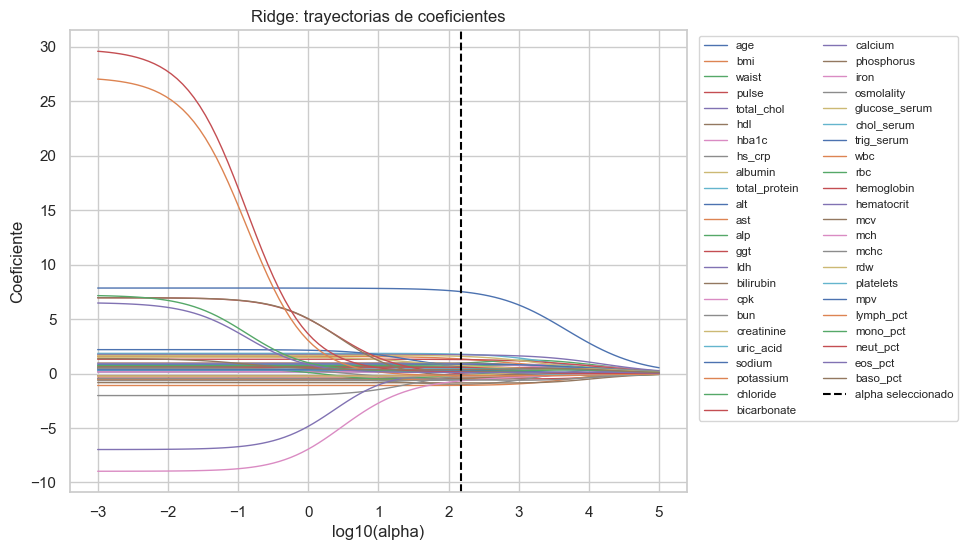

In [24]:
# Trayectoria de coeficientes Ridge
scaler_path = StandardScaler().fit(X_train)
X_train_scaled = scaler_path.transform(X_train)

ridge_coefs = np.asarray([Ridge(alpha=a).fit(X_train_scaled, y_train).coef_ for a in alphas])
plt.figure(figsize=(13, 6))
for j, name in enumerate(X_pen.columns):
    plt.plot(np.log10(alphas), ridge_coefs[:, j], lw=1, label=name)
plt.axvline(np.log10(ridge_search.best_params_["model__alpha"]), color="black",
            linestyle="--", label="alpha seleccionado")
plt.xlabel("log10(alpha)"); plt.ylabel("Coeficiente")
plt.title("Ridge: trayectorias de coeficientes")
plt.legend(bbox_to_anchor=(1.01, 1.0), loc="upper left", fontsize="x-small", ncol=2)
plt.subplots_adjust(right=0.60)
plt.show()

**Evolución de los coeficientes de Ridge**

En este gráfico podemos ver cómo cambian los coeficientes de nuestras 46 variables a medida que aumentamos el parámetro de regularización α.

Cada línea representa una variable predictora, mientras que el eje horizontal muestra los valores de α en escala logarítmica. Hemos utilizado esta escala porque estamos probando valores muy diferentes entre sí, desde 0,001 hasta 100.000.

Si nos fijamos en el gráfico, podemos observar que:

- **Con valores pequeños de α**, la penalización es muy débil y los coeficientes se parecen a los que obtendríamos con una regresión lineal ordinaria.
- **Conforme aumenta α**, los coeficientes van reduciendo su magnitud y acercándose progresivamente a cero. De esta forma, Ridge limita la influencia de los coeficientes y trata de conseguir un modelo más estable.
- **Con valores muy grandes de α**, la penalización es tan fuerte que los coeficientes se acercan mucho a cero. Esto puede ser contraproducente, porque el modelo termina perdiendo capacidad para recoger las relaciones entre las variables y la presión arterial.

Además, la línea negra discontinua señala el valor que hemos seleccionado mediante validación cruzada (**α ≈ 148,5**).

Lo interesante es que **Ridge no elimina directamente las variables**, sino que reduce sus coeficientes. Esto lo diferencia de Lasso, que veremos a continuación y que sí puede hacer que algunos coeficientes sean exactamente cero.

Por tanto, este gráfico nos permite entender visualmente cómo funciona la regularización: intentamos evitar coeficientes excesivamente grandes, pero sin penalizarlos tanto como para que el modelo pierda información importante.

### Regresión Lasso

In [25]:
lasso_pipe = Pipeline([("scaler", StandardScaler()), ("model", Lasso(max_iter=20000))])
lasso_search = GridSearchCV(lasso_pipe, {"model__alpha": alphas},
                            scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
lasso_search.fit(X_train, y_train)
print("Lasso: mejor alpha =", lasso_search.best_params_["model__alpha"],
      "| MSE CV =", round(-lasso_search.best_score_, 1))

/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/mercedeslopezcaballero/TFM

Lasso: mejor alpha = 0.02848035868435802 | MSE CV = 264.6


Ahora vamos a aplicar Lasso, utilizando el mismo conjunto de datos y el mismo procedimiento de validación cruzada que con Ridge.

La diferencia principal es que Lasso utiliza una penalización L1, que puede hacer que algunos coeficientes sean exactamente cero. Es decir, además de reducir los coeficientes, puede eliminar variables del modelo.

Después de probar los distintos valores de α, obtenemos un valor óptimo de **α ≈ 0,028**, con un **MSE medio de validación cruzada de 264,6**.

Este valor de α es bastante pequeño, lo que indica que el modelo seleccionado utiliza una penalización relativamente débil.

Aunque el MSE de validación cruzada es prácticamente igual al de Ridge, no podemos comparar directamente sus valores de α para decidir cuál regulariza más, ya que utilizan penalizaciones diferentes.

Por ahora, lo interesante es que ambos modelos han encontrado una configuración con un error de validación muy parecido. Más adelante veremos si también ocurre lo mismo cuando los evaluamos con los datos de test.

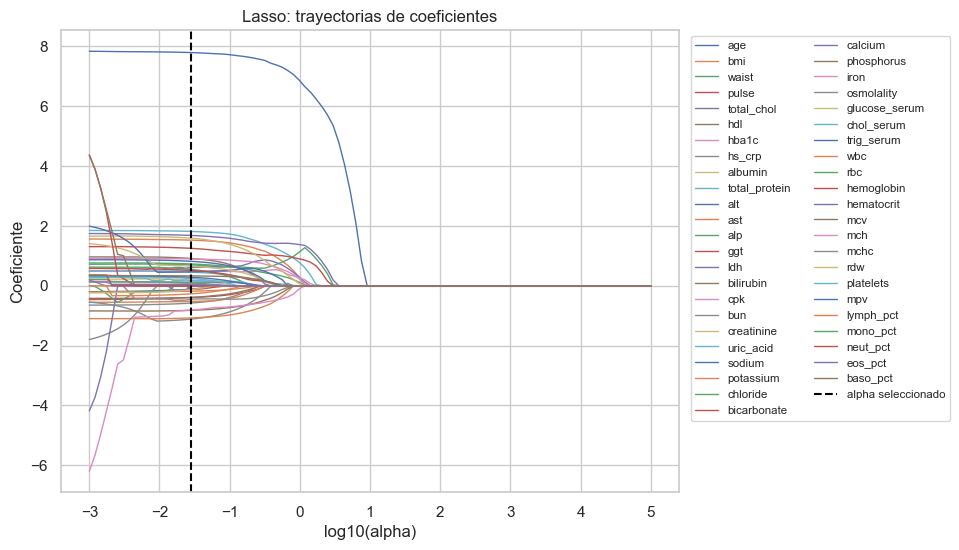

In [26]:
# Trayectoria de coeficientes Lasso
lasso_coefs = np.asarray([Lasso(alpha=a, max_iter=20000).fit(X_train_scaled, y_train).coef_ for a in alphas])
plt.figure(figsize=(13, 6))
for j, name in enumerate(X_pen.columns):
    plt.plot(np.log10(alphas), lasso_coefs[:, j], lw=1, label=name)
plt.axvline(np.log10(lasso_search.best_params_["model__alpha"]), color="black",
            linestyle="--", label="alpha seleccionado")
plt.xlabel("log10(alpha)"); plt.ylabel("Coeficiente")
plt.title("Lasso: trayectorias de coeficientes")
plt.legend(bbox_to_anchor=(1.01, 1.0), loc="upper left", fontsize="x-small", ncol=2)
plt.subplots_adjust(right=0.60)
plt.show()

**Evolución de los coeficientes de Lasso**

Este gráfico es parecido al que hemos visto anteriormente con Ridge. Cada línea representa el coeficiente de una variable y el eje horizontal muestra cómo va aumentando el parámetro α, utilizando una escala logarítmica.

Sin embargo, aquí encontramos una diferencia importante:

- **Cuando α es pequeño**, la penalización es débil y la mayoría de las variables mantienen coeficientes distintos de cero.
- **Conforme aumenta α**, algunos coeficientes van disminuyendo hasta llegar exactamente a cero. Cuando esto ocurre, Lasso está dejando de utilizar esas variables para realizar las predicciones.
- **Cuando α es muy grande**, cada vez quedan menos variables en el modelo. Esto puede simplificarlo bastante, pero también podemos perder información útil y empeorar las predicciones.

La línea negra discontinua indica el valor seleccionado mediante validación cruzada (**α ≈ 0,028**).

Si nos fijamos en su posición, vemos que está en una zona donde todavía se mantienen muchas variables. Esto nos indica que, para nuestro problema, el valor de α que consigue el menor error de validación **no es uno que elimine una gran cantidad de predictores**.

Por tanto, aunque Lasso puede utilizarse para seleccionar variables automáticamente, esto no significa que siempre vaya a quedarse únicamente con unas pocas. Dependerá de los datos y del valor de regularización que seleccionemos.

In [27]:
# Variables que conserva Lasso
lasso_model = lasso_search.best_estimator_.named_steps["model"]
lasso_coef = pd.Series(lasso_model.coef_, index=X_pen.columns)
keep = lasso_coef[lasso_coef != 0].sort_values(key=abs, ascending=False)
print("Nº de coeficientes no nulos:", (lasso_coef != 0).sum(), "de", len(lasso_coef))
print()
print(keep.round(3).to_string())

Nº de coeficientes no nulos: 42 de 46

age              7.795
total_protein    1.816
ldh              1.683
creatinine       1.590
bmi              1.526
ggt              1.252
bun             -1.112
potassium       -1.073
hdl              0.913
cpk              0.898
phosphorus      -0.818
trig_serum       0.818
mch             -0.812
alp              0.729
waist            0.696
glucose_serum    0.657
total_chol       0.616
hs_crp          -0.575
chloride         0.549
ast             -0.522
bicarbonate      0.515
hba1c            0.495
sodium           0.467
uric_acid        0.456
mchc            -0.446
pulse           -0.390
bilirubin       -0.389
baso_pct         0.331
mpv              0.286
lymph_pct       -0.268
platelets        0.243
albumin          0.188
wbc             -0.180
chol_serum       0.170
rdw             -0.126
calcium          0.123
alt             -0.109
hemoglobin      -0.108
mono_pct         0.096
iron             0.069
eos_pct          0.038
hematocrit      -0

**Interpretación de la selección de variables**

Una vez seleccionado el valor óptimo de α, vamos a comprobar qué variables ha conservado Lasso y cuáles ha eliminado.

En nuestro caso, **Lasso mantiene 42 de los 46 predictores iniciales**, por lo que únicamente ha eliminado cuatro variables.

Esto nos indica que, con la penalización seleccionada, Lasso no realiza una reducción demasiado grande del número de variables. Es decir, para conseguir el menor error de validación, el modelo sigue utilizando prácticamente toda la información disponible.

Si nos fijamos en los coeficientes, encontramos que la **edad (`age`) es la variable con mayor magnitud**, con un coeficiente de aproximadamente 7,80. Después aparecen `total_protein`, `ldh`, `creatinine`, `bmi` y `ggt`, aunque con coeficientes bastante menores.

Hay que tener en cuenta que estos coeficientes corresponden a variables estandarizadas, por lo que representan cambios asociados a una desviación típica adicional de cada predictor, manteniendo los demás constantes dentro del modelo. Además, su valor también está condicionado por la regularización y por las correlaciones entre variables.

En cuanto a las cuatro variables que Lasso ha eliminado, encontramos:

- **`osmolality`:** está bastante relacionada con otras variables, como `sodium`, por lo que parte de su información puede estar recogida por otros predictores.
- **`rbc` y `mcv`:** son indicadores relacionados con los glóbulos rojos y presentan relaciones con otras variables del hemograma.
- **`neut_pct`:** representa el porcentaje de neutrófilos, que está relacionado con los porcentajes de otros tipos de glóbulos blancos.

Esto puede ayudar a entender por qué Lasso ha decidido eliminar esas variables, aunque no podemos asegurar que esa sea la única razón.

También es importante aclarar que **eliminar una variable no significa que no tenga ninguna relación con la presión arterial**. Puede ocurrir que su información ya esté representada por otros predictores o que, con la penalización seleccionada, no aporte suficiente mejora al modelo.

En definitiva, en nuestro caso Lasso ha realizado una selección bastante limitada. Su principal interés no parece estar en conseguir un modelo con muy pocas variables, sino en regularizar los coeficientes para intentar obtener predicciones más estables ante la presencia de variables correlacionadas.

### Comparación de OLS, Ridge, Lasso y Elastic Net

In [ ]:
elastic_search = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("model", ElasticNet(max_iter=10000))]),
    {"model__alpha": np.logspace(-3, 3, 20), "model__l1_ratio": [0.5, 0.9, 0.99, 1.0]},
    scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
elastic_search.fit(X_train, y_train)

models = {
    "OLS": ols_pipe,
    "Ridge": ridge_search.best_estimator_,
    "Lasso": lasso_search.best_estimator_,
    "Elastic Net": elastic_search.best_estimator_,
}
results = []
for name, model in models.items():
    pred = model.predict(X_test)
    results.append({"Modelo": name,
                    "MSE test": mean_squared_error(y_test, pred),
                    "R² test": r2_score(y_test, pred)})
display(pd.DataFrame(results).sort_values("MSE test").round(3))

/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/mercedeslopezcaballero/TFM

,Modelo,MSE test,R² test
2,Lasso,235.623,0.283
3,Elastic Net,235.919,0.282
1,Ridge,236.099,0.282
0,OLS,236.519,0.281


Una vez ajustados los modelos, vamos a compararlos para comprobar si la regularización ha conseguido mejorar las predicciones respecto a la regresión lineal ordinaria.

Además de Ridge y Lasso, hemos incluido **Elastic Net**, una técnica que combina las penalizaciones L1 y L2. Es decir, intenta aprovechar tanto la capacidad de Ridge para reducir y estabilizar los coeficientes como la posibilidad de Lasso de seleccionar variables.

Para hacer una comparación justa, hemos utilizado los mismos datos de entrenamiento y test en los cuatro modelos. Además, los parámetros de regularización se han seleccionado mediante validación cruzada, sin utilizar el conjunto de test.

Si nos fijamos en los resultados, vemos que:

- **Lasso:** obtiene el menor MSE (235,623) y el mayor R² (0,283), por lo que es el modelo que consigue los mejores resultados en nuestro conjunto de test.
- **Elastic Net:** queda en segunda posición, con un MSE de 235,919 y un R² de 0,282, prácticamente iguales a los de Lasso.
- **Ridge:** obtiene un MSE de 236,099 y un R² de 0,282, también muy parecido a los anteriores.
- **OLS:** presenta el MSE más elevado (236,519) y el R² más bajo (0,281), aunque la diferencia respecto a los otros modelos es bastante pequeña.

Por tanto, **los tres modelos regularizados mejoran ligeramente los resultados de OLS**, pero tampoco podemos decir que la mejora sea especialmente importante.

De hecho, entre Lasso y OLS hay una diferencia de menos de 1 punto en el MSE y de apenas 0,002 en el R². Esto nos indica que, aunque Lasso haya obtenido el mejor resultado en esta partición de test, no tenemos evidencia suficiente para afirmar que sea claramente superior

## 5. Análisis mediante PCA

Como hemos visto en los apartados anteriores, nuestro conjunto de datos contiene muchas variables relacionadas entre sí. Por ejemplo, la hemoglobina y el hematocrito presentan una correlación muy elevada, por lo que parte de la información que aportan es similar.

Hasta ahora hemos utilizado Ridge y Lasso para intentar controlar los problemas que esto puede ocasionar en una regresión. Sin embargo, existe otra forma de trabajar con tantas variables: **reducir su número sin perder demasiada información**.

Para ello vamos a utilizar el **Análisis de Componentes Principales (PCA)**.

La idea es bastante sencilla: en lugar de trabajar directamente con nuestras 46 variables, PCA crea otras nuevas, llamadas *componentes principales*, que son combinaciones de las originales. Podemos imaginarlas como una especie de «mega-indicadores» que resumen la información de varias variables a la vez.

Estas componentes tienen dos características importantes:

- **No están correlacionadas entre sí**, por lo que no contienen información lineal redundante.
- **Están ordenadas según la varianza que explican**. La primera recoge la mayor cantidad posible de variabilidad, la segunda recoge la mayor cantidad posible de la que queda, y así sucesivamente.

Lo que queremos comprobar es si podemos representar nuestros datos utilizando menos componentes que variables originales, pero conservando una parte importante de su variabilidad.

Para este análisis utilizaremos los mismos **46 predictores cuantitativos** que seleccionamos anteriormente, con sus transformaciones logarítmicas correspondientes. En total tenemos **9.075 participantes con información completa** para estas variables.

Como PCA es una técnica **no supervisada**, no utilizaremos la presión sistólica (`sbp`) para construir las componentes. Simplemente queremos estudiar cómo se relacionan las variables entre sí y qué estructura tienen nuestros datos.

Por último, antes de aplicar PCA, estandarizaremos las variables para que todas tengan media 0 y desviación típica 1. Esto es importante porque estamos mezclando medidas con unidades muy diferentes y no queremos que una variable tenga más peso simplemente porque sus valores numéricos sean mayores.

En este apartado utilizaremos todos los casos completos para estudiar la estructura general de los datos. Más adelante, cuando usemos componentes para realizar predicciones, separaremos correctamente los datos de entrenamiento y test.

In [30]:
# Primero ponemos todas las variables en la misma escala (media 0, desviación 1), para que ninguna "pese" más solo por tener números más grandes.
X_scaled = StandardScaler().fit_transform(X_pen)
pca = PCA()
Z = pca.fit_transform(X_scaled)

loadings = pca.components_          # filas = componentes (direcciones φ)
var = pca.explained_variance_       # varianza de cada Zj
ratio = pca.explained_variance_ratio_

print("Resumen del modelo PCA (varianza explicada):")
summary_pca = pd.DataFrame({
    "Desv. típica": np.sqrt(var),
    "Varianza": var,
    "Proporción": ratio,
    "Acumulada": np.cumsum(ratio),
}, index=[f"PC{i+1}" for i in range(len(var))])
display(summary_pca.head(10).round(3))

# ¿Cuántas componentes hacen falta para alcanzar distintos niveles de varianza?
print()
for thr in [0.7, 0.8, 0.9]:
    k = int(np.searchsorted(np.cumsum(ratio), thr) + 1)
    print(f"  {int(thr*100)}% de varianza -> {k} componentes")

Resumen del modelo PCA (varianza explicada):


/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: invalid value encountered in matmul
  C = X.T @ X
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/decomposition

,Desv. típica,Varianza,Proporción,Acumulada
PC1,2.227,4.961,0.108,0.108
PC2,2.041,4.168,0.091,0.198
PC3,1.820,3.312,0.072,0.270
PC4,1.605,2.577,0.056,0.326
PC5,1.565,2.450,0.053,0.380
PC6,1.421,2.018,0.044,0.424
PC7,1.412,1.993,0.043,0.467
PC8,1.318,1.737,0.038,0.505
PC9,1.275,1.625,0.035,0.540
PC10,1.243,1.546,0.034,0.574



  70% de varianza -> 15 componentes
  80% de varianza -> 20 componentes
  90% de varianza -> 27 componentes


**Resumen del modelo PCA**

Una vez aplicado PCA, obtenemos 46 componentes principales, tantas como variables originales. Sin embargo, no todas contienen la misma cantidad de información.

En la tabla podemos ver que la **primera componente (PC1) explica aproximadamente el 10,8 % de la variabilidad total** de nuestros datos. La segunda explica un 9,1 % y la tercera un 7,2 %.

Esto significa que, si utilizáramos únicamente PC1, conservaríamos alrededor del 10,8 % de la variabilidad original. Si utilizáramos PC1 y PC2, conservaríamos aproximadamente el 19,8 %.

Como vemos, la información no está concentrada únicamente en las primeras componentes, sino que está bastante repartida entre varias de ellas.

Esto ya nos da una pista de que **no vamos a poder reducir las 46 variables a solo dos o tres componentes sin perder una parte importante de la variabilidad**.

Más adelante veremos cuántas componentes necesitamos para conservar distintos porcentajes de información y si realmente nos compensa realizar esa reducción.

In [31]:
# Verificación: explained_variance_ == valores singulares^2 / (n-1)
U, S, Vt = np.linalg.svd(X_scaled, full_matrices=False)
print("¿explained_variance_ == S²/(n-1)?", np.allclose(var, S**2 / (len(X_scaled) - 1)))

# Justificación de la desviación típica de la primera componente
print()
print("Desviación típica de PC1:", round(np.sqrt(var[0]), 3))
print("Varianza total (suma autovalores):", round(var.sum(), 2), "= nº de variables:", X_pen.shape[1])

¿explained_variance_ == S²/(n-1)? True

Desviación típica de PC1: 2.227
Varianza total (suma autovalores): 46.01 = nº de variables: 46


**Justificación de la desviación típica de la primera componente**

Una de las cosas que nos interesa conocer es la desviación típica de PC1, que en nuestro caso es aproximadamente **2,227**.

Para entender de dónde sale este valor, tenemos que recordar que PCA busca componentes que recojan la mayor cantidad posible de variabilidad de nuestros datos.

Como hemos estandarizado las 46 variables originales, cada una tiene una varianza aproximadamente igual a 1. Por tanto, la varianza total del conjunto es aproximadamente 46.

Sin embargo, al construir las componentes principales, esa variabilidad se reparte de forma diferente: las primeras componentes concentran más varianza que las últimas.

En nuestro caso, **PC1 tiene una varianza de 4,961**, que es la mayor de todas las componentes.

Como la desviación típica es la raíz cuadrada de la varianza, obtenemos $\sigma_{PC1}=\sqrt{4,961}\approx 2,227$


Por tanto, la desviación típica de PC1 es 2,227 porque esta componente recoge una varianza de aproximadamente 4,961.

Esto también explica por qué PC1 representa alrededor del 10,8 % de la variabilidad total $\frac{4,961}{46,01}\cdot 100\approx 10,8\% $


Además, hemos comprobado mediante la descomposición en valores singulares (SVD) que la varianza calculada por PCA coincide con la obtenida a partir de los valores singulares.

En definitiva, **PC1 concentra más variabilidad que cualquiera de las variables originales estandarizadas por separado**, pero sigue representando una parte relativamente pequeña de la variabilidad total del conjunto.

**Scree plot y varianza acumulada**

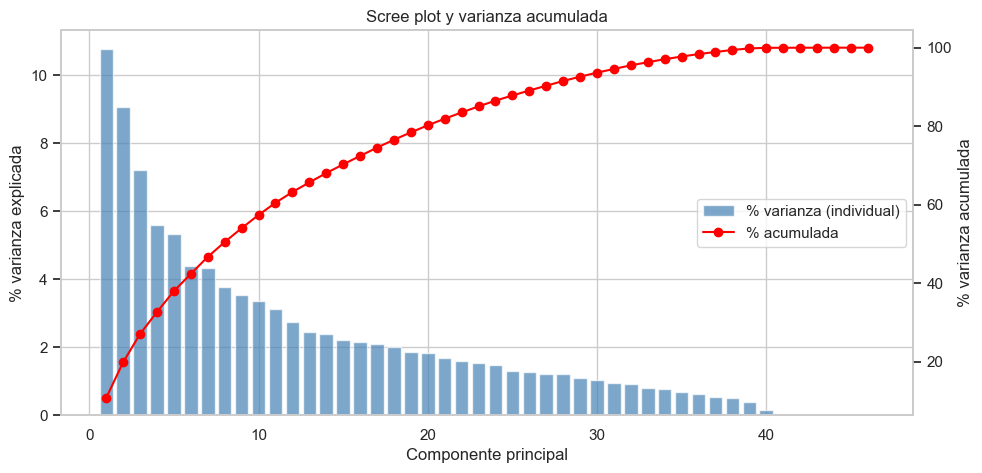

In [33]:
fig, ax1 = plt.subplots(figsize=(11, 5))
comp_idx = np.arange(1, len(var) + 1)
ax1.bar(comp_idx, ratio * 100, color="steelblue", alpha=0.7, label="% varianza (individual)")
ax1.set_xlabel("Componente principal"); ax1.set_ylabel("% varianza explicada")

ax2 = ax1.twinx()
ax2.plot(comp_idx, np.cumsum(ratio) * 100, color="red", marker="o", label="% acumulada")
ax2.set_ylabel("% varianza acumulada")
ax2.grid(False)

l1, lb1 = ax1.get_legend_handles_labels()
l2, lb2 = ax2.get_legend_handles_labels()
ax1.legend(l1 + l2, lb1 + lb2, loc="center right")
plt.title("Scree plot y varianza acumulada")
plt.show()

En este gráfico podemos ver cuánta variabilidad de nuestros datos consigue recoger cada componente principal y cómo aumenta la varianza explicada conforme vamos utilizando más componentes.

Las **barras azules** representan el porcentaje de varianza que explica cada componente de manera individual, mientras que la **línea roja** muestra la varianza acumulada, es decir, la suma de los porcentajes de todas las componentes que vamos incluyendo.

Si nos fijamos en los resultados, vemos que las primeras componentes son las que más información recogen, aunque la varianza explicada va disminuyendo de forma bastante gradual:

- **PC1:** explica aproximadamente el 10,8 % de la variabilidad total.
- **PC1 y PC2 juntas:** explican alrededor del 19,8 %.
- **Las primeras 8 componentes:** acumulan un 50,5 % de la varianza.
- **Las primeras 10 componentes:** acumulan un 57,4 %.

Por tanto, aunque las primeras componentes recogen más información que las siguientes, no encontramos un punto en el que la varianza explicada caiga de forma muy brusca. Esto nos indica que la información está bastante repartida entre las distintas componentes.

**¿Cuántas componentes necesitamos para conservar la mayor parte de la información?**

Como también hemos calculado en la celda anterior:

| Varianza que queremos conservar | Componentes necesarias |
|---|---|
| 70 % | 15 |
| 80 % | 20 |
| 90 % | 27 |

Por ejemplo, si decidimos conservar el 80 % de la varianza, podríamos pasar de nuestras 46 variables originales a 20 componentes principales. Estaríamos reduciendo el número de dimensiones a menos de la mitad, pero perdiendo aproximadamente un 20 % de la variabilidad original.

En cambio, si únicamente utilizáramos las dos primeras componentes, perderíamos alrededor del 80 % de la varianza, por lo que no sería una representación demasiado completa de los datos.

En definitiva, **PCA sí nos permite reducir la dimensionalidad de nuestro conjunto de datos, pero no de una forma tan drástica como podríamos esperar**. Para conservar una parte importante de la variabilidad necesitamos bastantes componentes, ya que nuestros 46 indicadores contienen información que no se puede resumir únicamente en dos o tres dimensiones.

Esto no significa que PCA no sea útil. Además de reducir dimensiones, también nos permite estudiar cómo se relacionan las variables y detectar grupos de indicadores que comparten información, algo que veremos en los siguientes gráficos.

In [34]:
loadings_df = pd.DataFrame(loadings.T, index=X_pen.columns,
                           columns=[f"PC{i+1}" for i in range(X_pen.shape[1])])
for pc in ["PC1", "PC2", "PC3"]:
    top = loadings_df[pc].reindex(loadings_df[pc].abs().sort_values(ascending=False).index).head(6)
    print(f"{pc} — variables con mayor |peso|:")
    print(top.round(3).to_string())
    print()

PC1 — variables con mayor |peso|:
hemoglobin    0.383
hematocrit    0.351
mch           0.287
rdw          -0.277
mchc          0.274
iron          0.269

PC2 — variables con mayor |peso|:
waist         0.358
bmi           0.316
hs_crp        0.265
hba1c         0.262
trig_serum    0.252
ggt           0.248

PC3 — variables con mayor |peso|:
osmolality    0.359
age           0.293
bun           0.287
sodium        0.262
mcv           0.257
rbc          -0.254



**Interpretación de las componentes principales**

Una vez que sabemos cuánta variabilidad explica cada componente, vamos a intentar entender qué información está recogiendo cada una.

Para ello nos fijamos en las **cargas (*loadings*)**, que nos indican cuánto participa cada variable original en la construcción de una componente. Cuanto mayor sea el valor absoluto de una carga, mayor será su peso en esa componente. Además, el signo nos indica si la variable contribuye en sentido positivo o negativo.

En nuestro caso, encontramos lo siguiente:

- **PC1:** las variables que más destacan son `hemoglobin` (0,383), `hematocrit` (0,351), `mch` (0,287), `rdw` (-0,277), `mchc` (0,274) e `iron` (0,269). Todas ellas están relacionadas con los glóbulos rojos, la hemoglobina o el hierro. Por tanto, podemos interpretar esta primera componente como una especie de indicador que resume principalmente características del hemograma.

- **PC2:** encontramos `waist` (0,358), `bmi` (0,316), `hs_crp` (0,265), `hba1c` (0,262), `trig_serum` (0,252) y `ggt` (0,248). Aquí aparecen medidas corporales e indicadores relacionados con la inflamación, la glucosa y los lípidos. Por eso, esta componente parece recoger principalmente información relacionada con la adiposidad y la salud metabólica.

- **PC3:** destacan `osmolality` (0,359), `age` (0,293), `bun` (0,287), `sodium` (0,262), `mcv` (0,257) y `rbc` (-0,254). En este caso, la interpretación es algo menos directa, porque combina variables relacionadas con el equilibrio de líquidos y electrolitos, la función renal, la edad y el hemograma.

Hay que tener en cuenta que **las componentes no son variables clínicas reales**, sino combinaciones matemáticas de nuestras variables originales. Por eso, cuando decimos que PC2 representa una dimensión metabólica, estamos interpretando el patrón que encontramos, no afirmando que PCA haya identificado directamente una enfermedad.

Además, el signo de las componentes es arbitrario: si cambiáramos todos los signos de una componente, seguiríamos representando exactamente la misma información.

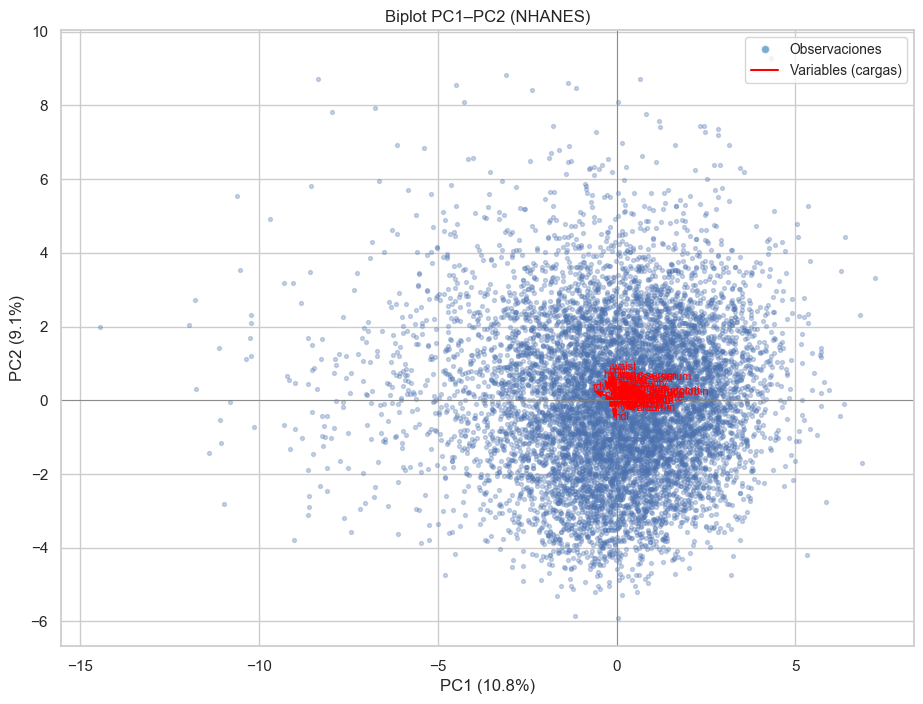

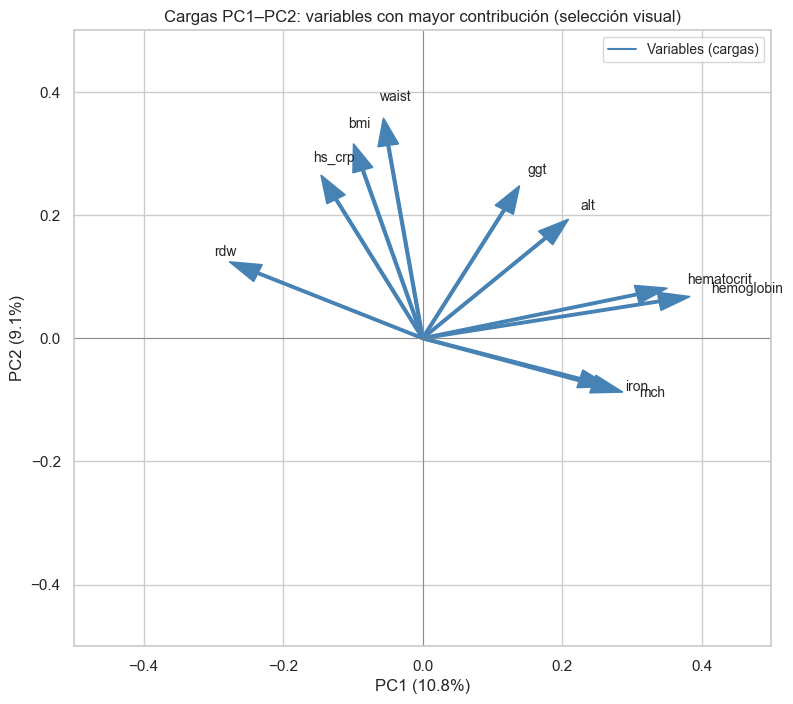

In [35]:
# Biplot PC1-PC2
comp = pca.components_.T * np.sqrt(pca.explained_variance_)
fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(Z[:, 0], Z[:, 1], s=8, alpha=0.3)
for j, name in enumerate(X_pen.columns):
    ax.arrow(0, 0, comp[j, 0], comp[j, 1], color="red", width=0.002,
             head_width=0.15, length_includes_head=True)
    ax.text(comp[j, 0] * 1.12, comp[j, 1] * 1.12, name, color="red", fontsize=8)
ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
ax.set_xlabel(f"PC1 ({ratio[0]*100:.1f}%)"); ax.set_ylabel(f"PC2 ({ratio[1]*100:.1f}%)")
ax.set_title("Biplot PC1–PC2 (NHANES)")

# Leyenda: qué representa cada elemento del biplot
biplot_legend = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#1f77b4",
           markersize=6, alpha=0.6, label="Observaciones"),
    Line2D([0], [0], color="red", lw=1.5, label="Variables (cargas)"),
]
ax.legend(handles=biplot_legend, fontsize="small", loc="upper right")
plt.show()

# Lectura alternativa: solo las variables con mayor contribución a PC1–PC2
# (selección visual de las ~10 con mayor norma de cargas en el plano PC1–PC2).
contrib = np.sqrt(loadings[0, :] ** 2 + loadings[1, :] ** 2)
top_idx = np.argsort(contrib)[::-1][:10]

fig, ax = plt.subplots(figsize=(9, 8))
for j in top_idx:
    x = loadings[0, j]
    y = loadings[1, j]
    ax.arrow(0, 0, x, y, color="steelblue", width=0.004,
             head_width=0.03, length_includes_head=True)
    ax.text(x * 1.08, y * 1.08, X_pen.columns[j], fontsize=10)
ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
ax.set_xlim(-0.5, 0.5); ax.set_ylim(-0.5, 0.5)
ax.set_xlabel(f"PC1 ({ratio[0]*100:.1f}%)"); ax.set_ylabel(f"PC2 ({ratio[1]*100:.1f}%)")
ax.set_title("Cargas PC1–PC2: variables con mayor contribución (selección visual)")
ax.legend(handles=[Line2D([0], [0], color="steelblue", lw=1.5,
                          label="Variables (cargas)")], fontsize="small", loc="upper right")
plt.show()

**Interpretación del biplot**

En estos gráficos podemos ver cómo se relacionan las variables originales con las dos primeras componentes principales.

En el primer gráfico aparecen dos elementos:

- **Los puntos azules:** cada uno representa a un participante de NHANES, situado según sus valores en PC1 y PC2. Los participantes que aparecen cerca tienen perfiles parecidos en estas dos componentes, aunque pueden diferenciarse en otras.
- **Las flechas rojas:** representan las variables originales y nos ayudan a interpretar qué información está recogiendo cada componente.

Para entender las flechas, podemos fijarnos en tres cosas:

- **Su dirección:** las variables cuyas flechas apuntan en direcciones parecidas tienden a estar relacionadas positivamente. Si apuntan en sentidos opuestos, su relación suele ser negativa.
- **Su longitud:** las flechas más largas tienen una representación más marcada en el plano de las dos primeras componentes, aunque su longitud también depende de cómo se hayan escalado para dibujarlas.
- **Su orientación respecto a los ejes:** si una flecha apunta principalmente en horizontal, está más relacionada con PC1; si apunta principalmente en vertical, con PC2.

El problema es que tenemos 46 variables y, al representarlas todas juntas, muchas flechas y nombres se solapan. Por eso hemos añadido un segundo gráfico que muestra únicamente las diez variables con mayores cargas conjuntas en PC1 y PC2.

En este segundo gráfico se aprecia mejor lo que ya habíamos observado al estudiar las cargas:

- **PC1 (eje horizontal):** destacan especialmente las variables relacionadas con el hemograma, como `hemoglobin` y `hematocrit`. Esto refuerza nuestra interpretación de que la primera componente resume principalmente información sobre los glóbulos rojos y la hemoglobina.
- **PC2 (eje vertical):** encontramos variables como `waist` y `bmi`, relacionadas con las medidas corporales, junto con otros indicadores metabólicos. Por tanto, esta componente parece representar una dimensión relacionada con la adiposidad y el metabolismo.

También podemos observar que algunas variables apuntan en direcciones similares, lo que indica que comparten parte de su información. Esto tiene sentido, ya que anteriormente habíamos encontrado correlaciones elevadas entre algunos de estos indicadores.

Eso sí, **hay que tener en cuenta una limitación importante**: PC1 y PC2 explican conjuntamente alrededor del 19,8 % de la variabilidad total. Por tanto, estos gráficos nos permiten visualizar algunas relaciones interesantes, pero no representan toda la información de nuestros datos.

En definitiva, el biplot nos ayuda a entender qué están resumiendo las primeras componentes y qué grupos de variables se comportan de forma parecida. Sin embargo, como la variabilidad está bastante repartida entre las 46 componentes, necesitamos considerar más de dos para obtener una representación más completa del conjunto.

### Extensión (opcional): PCR y PLS

Hasta ahora hemos utilizado PCA para resumir la información de nuestras 46 variables originales. Sin embargo, también podemos aprovechar las componentes para intentar predecir la presión arterial sistólica (`sbp`).

Para ello vamos a comparar dos técnicas:

- **PCR (Principal Component Regression):** primero utiliza PCA para construir las componentes principales y después aplica una regresión lineal sobre ellas. El detalle importante es que PCA construye estas componentes sin tener en cuenta la presión arterial, sino únicamente la variabilidad de los predictores.
- **PLS (Partial Least Squares):** también construye nuevas componentes a partir de las variables originales, pero en este caso sí tiene en cuenta la presión arterial. Es decir, intenta encontrar componentes que no solo resuman información, sino que también resulten útiles para predecir nuestra variable respuesta.

Podemos decir que **PCR primero resume los datos y después intenta predecir, mientras que PLS construye los resúmenes pensando ya en la predicción**.

En ambos casos tenemos que decidir cuántas componentes utilizar. Si escogemos muy pocas, podemos perder información importante; pero utilizar demasiadas tampoco garantiza obtener mejores resultados.

Por eso, al igual que hicimos con Ridge y Lasso, vamos a utilizar validación cruzada de 10 particiones para seleccionar el número de componentes que consigue el menor error medio.

Para PCR probaremos desde 1 hasta 46 componentes, mientras que para PLS evaluaremos desde 1 hasta 20. Utilizaremos los mismos datos de entrenamiento y las mismas particiones de validación para poder comparar los resultados.

In [36]:
pcr_search = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("pca", PCA()), ("model", LinearRegression())]),
    {"pca__n_components": range(1, X_pen.shape[1] + 1)},
    scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
pcr_search.fit(X_train, y_train)

n_pls = 20
pls_search = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("pls", PLSRegression(scale=False))]),
    {"pls__n_components": range(1, n_pls + 1)},
    scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
pls_search.fit(X_train, y_train)

print("PCR: m =", pcr_search.best_params_["pca__n_components"], "| MSE CV =", round(-pcr_search.best_score_, 1))
print("PLS: m =", pls_search.best_params_["pls__n_components"], "| MSE CV =", round(-pls_search.best_score_, 1))

/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: invalid value encountered in matmul
  C = X.T @ X
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/decomposition

PCR: m = 40 | MSE CV = 264.6
PLS: m = 16 | MSE CV = 264.6


/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: divide by zero encountered in matmul
  B = (u @ vh[:rank]).conj().T
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: overflow encountered in matmul
  B = (u @ vh[:rank]).conj().T
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: invalid value encountered in matmul
  B = (u @ vh[:rank]).conj().T
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/cross_decomposition/_pls.py:534: RuntimeWarning: divide by zero encountered in matmul
  Ypred = X @ self.coef_.T + self.intercept_
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/cross_decomposition/_pls.py:534: RuntimeWarning: overflow encountered in matmul
  Ypred = X @ self.coef_.T + self.intercept_
/Users/mercedeslopezcaballero/TFM/TEP/ven

**Resultados de PCR y PLS**

Después de probar los distintos números de componentes mediante validación cruzada, obtenemos los siguientes resultados:

- **PCR:** selecciona 40 componentes, con un MSE medio de validación cruzada de aproximadamente 264,6.
- **PLS:** selecciona 16 componentes, con un MSE medio de validación cruzada también de aproximadamente 264,6.

Lo primero que llama la atención es que **ambos modelos consiguen prácticamente el mismo error, pero PLS necesita bastantes menos componentes**.

Esto tiene sentido si recordamos cómo funciona cada técnica. PCR selecciona las componentes que explican más variabilidad de los predictores, pero esas componentes no tienen por qué ser las más útiles para predecir la presión arterial.

En cambio, PLS utiliza también la información de `sbp` para construir sus componentes. Por eso puede encontrar direcciones que estén relacionadas con nuestra variable respuesta sin necesidad de conservar tantas dimensiones.

En nuestro caso, **PLS consigue un resultado predictivo muy parecido al de PCR utilizando 16 componentes en lugar de 40**.

Esto nos muestra que las componentes que más variabilidad explican no tienen por qué ser necesariamente las que más nos ayudan a realizar una predicción.

Eso sí, estos resultados corresponden a la validación cruzada. Por tanto, podemos afirmar que PLS necesita menos componentes para alcanzar un error de validación similar, pero no que sea necesariamente superior en cualquier conjunto de datos.

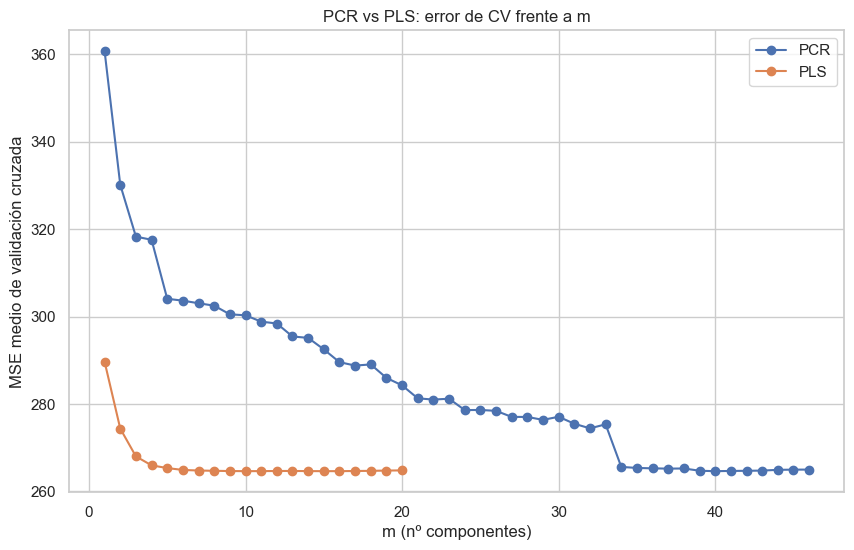

In [38]:
mses_pcr = -pcr_search.cv_results_["mean_test_score"]
mses_pls = -pls_search.cv_results_["mean_test_score"]

plt.plot(range(1, X_pen.shape[1] + 1), mses_pcr, marker="o", label="PCR")
plt.plot(range(1, n_pls + 1), mses_pls, marker="o", label="PLS")
plt.xlabel("m (nº componentes)"); plt.ylabel("MSE medio de validación cruzada")
plt.title("PCR vs PLS: error de CV frente a m")
plt.legend()
plt.show()

**Comparación gráfica de PCR y PLS**

En este gráfico podemos ver cómo cambia el error medio de validación cruzada a medida que aumentamos el número de componentes de cada modelo.

El eje horizontal representa el número de componentes utilizadas (`m`), mientras que el vertical muestra el MSE medio obtenido mediante validación cruzada. Como siempre, cuanto menor sea el error, mejores serán las predicciones.

Si nos fijamos en las dos curvas, observamos que:

- **PCR:** al utilizar pocas componentes, el error es relativamente elevado. Conforme añadimos más, va disminuyendo hasta alcanzar su mínimo con 40 componentes. Esto nos indica que las primeras componentes de PCA, aunque resumen bastante variabilidad, no contienen por sí solas toda la información que necesita el modelo para predecir bien la presión sistólica.
- **PLS:** consigue reducir el error utilizando menos componentes y alcanza su mínimo con 16. Esto se debe a que las componentes se construyen teniendo en cuenta su relación con la presión arterial.

Por tanto, el gráfico confirma lo que habíamos observado en los resultados anteriores: **PLS consigue un error parecido al de PCR utilizando menos de la mitad de componentes**.

Lo interesante es que aquí vemos claramente la diferencia entre **resumir información y conservar información útil para predecir**. PCA se centra en explicar la variabilidad de los datos, mientras que PLS también tiene en cuenta la variable que queremos predecir.

En definitiva, para nuestro conjunto de datos, PLS parece una alternativa más eficiente en cuanto al número de componentes necesarias, aunque ambos modelos consiguen prácticamente el mismo error de validación.

## 6. Regresión logística

Hasta ahora hemos utilizado distintos modelos para intentar predecir la presión arterial sistólica (`sbp`), que es una variable numérica. Sin embargo, también podemos plantear otro tipo de problema: en lugar de predecir un valor concreto, podemos intentar **clasificar a los participantes en dos grupos**.

Para ello vamos a utilizar la **regresión logística**, que es una técnica de clasificación que nos permite estimar la probabilidad de que ocurra un determinado evento.

En nuestro caso, queremos estudiar si una persona tiene hipertensión diagnosticada. Para ello utilizaremos la variable `hypertension_dx`, que puede tomar dos valores:

- **`yes`:** el participante tiene un diagnóstico de hipertensión.
- **`no`:** el participante no tiene un diagnóstico de hipertensión.

Como únicamente tenemos dos posibles resultados, estamos ante un problema de **clasificación binaria**.

La diferencia respecto a la regresión lineal es que ahora el modelo no nos devuelve directamente una presión arterial, sino una probabilidad entre 0 y 1. Por ejemplo, si obtenemos 0,75, significa que el modelo estima una probabilidad del 75 % de pertenecer al grupo con hipertensión diagnosticada.

Después podemos convertir esa probabilidad en una clasificación. Por defecto, utilizaremos un umbral de 0,5: si la probabilidad estimada es igual o superior a 0,5, clasificaremos al participante como `yes`; en caso contrario, como `no`.

Eso sí, hay que tener en cuenta que **estamos prediciendo un diagnóstico registrado en el dataset, no diagnosticando médicamente a una persona**. Además, estas probabilidades son estimaciones del modelo y no tienen por qué coincidir exactamente

In [39]:
df["hypertension_dx"].value_counts(dropna=False)

hypertension_dx
no     6719
yes    4005
NaN      15
Name: count, dtype: int64

Lo primero que hemos hecho es comprobar cuántos participantes pertenecen a cada grupo.

Como vemos, tenemos **6.719 personas sin hipertensión diagnosticada y 4.005 con diagnóstico**, además de 15 participantes para los que no disponemos de esta información.

Por tanto, tenemos más personas sin diagnóstico que con él, aunque ambos grupos cuentan con bastantes observaciones.

Esto es importante porque, si uno de los grupos fuera muchísimo más pequeño que el otro, podría resultar más difícil entrenar y evaluar correctamente el modelo. En nuestro caso existe cierto desequilibrio, pero no es especialmente extremo.

Más adelante tendremos en cuenta esta distribución al separar los datos de entrenamiento y test, para que ambos conjuntos mantengan aproximadamente la misma proporción de participantes de cada clase.

In [42]:
# Predictores: edad, IMC, sexo, colesterol total, HDL y tabaco
cols_log = ["hypertension_dx", "age", "bmi", "sex", "total_chol", "hdl", "smoking"]
d_log = df[cols_log].dropna()
d_log = d_log[d_log["hypertension_dx"].isin(["yes", "no"])].copy()
d_log["y"] = (d_log["hypertension_dx"] == "yes").astype(int)
d_log = pd.get_dummies(
    d_log,
    columns=["sex", "smoking"],
    drop_first=True,
    dtype=int
)
feats = [c for c in d_log.columns if c not in ("hypertension_dx", "y")]
X_log = d_log[feats]
y_log = d_log["y"]

print("Observaciones:", d_log.shape[0], "| Prevalencia de hipertensión:", round(y_log.mean(), 3))

Observaciones: 9938 | Prevalencia de hipertensión: 0.372


Para intentar predecir el diagnóstico de hipertensión hemos seleccionado algunas variables que podrían estar relacionadas con él:

- **Edad (`age`) e IMC (`bmi`):** porque anteriormente hemos encontrado una relación positiva entre estas variables y la presión arterial.
- **Colesterol total (`total_chol`) y HDL (`hdl`):** para incluir algunos indicadores relacionados con la salud cardiovascular.
- **Sexo (`sex`) y tabaquismo (`smoking`):** para tener en cuenta otras características y hábitos de los participantes.

Como hicimos en la regresión lineal múltiple, convertimos las variables cualitativas en columnas binarias mediante `get_dummies()`, de manera que podamos utilizarlas en el modelo.

También transformamos `hypertension_dx` en una variable numérica llamada `y`, donde **1 representa tener hipertensión diagnosticada y 0 representa no tenerla**.

Por último, eliminamos los registros que tengan valores ausentes en alguna de las variables seleccionadas. Después de esta limpieza, nos quedamos con **9.938 participantes**, de los cuales aproximadamente el **37,2 % tiene hipertensión diagnosticada**.

Esta proporción corresponde a las observaciones que utilizaremos en nuestro análisis. No debemos interpretarla directamente como la prevalencia de hipertensión en toda la población estadounidense, ya que para realizar estimaciones poblacionales con NHANES habría que tener en cuenta su diseño muestral y los pesos correspondientes.

### 6.2 Ajuste e interpretación (odds ratios)

>  Nota (asociación vs. predicción): el modelo de esta sección (6.2) se ajusta sobre **todos los datos** (n = 9.938) y su objetivo es **interpretar asociaciones** mediante odds ratios. En la sección 6.3 se ajusta un **modelo distinto** con partición entrenamiento/test, cuyo objetivo es **evaluar la capacidad predictiva** (accuracy, AUC, matriz de confusión). Son dos objetivos —y dos modelos— distintos, no contradictorios.


>  ¿Qué es una "odds" y un "odds ratio"?
> - La **odds** es la relación "casos sí frente a casos no" (p. ej., 3 personas con hipertensión por cada 1 sin ella → odds = 3).
> - El **odds ratio (OR)** compara esa relación entre dos grupos. Un OR de 1.07 por año de edad significa "por cada año más, la odds de hipertensión se multiplica por 1.07". Regla práctica: **OR = 1** → no cambia; **OR > 1** → aumenta; **OR < 1** → disminuye. Y ojo: una odds **no** es lo mismo que una probabilidad.

In [43]:
# statsmodels para interpretación (coeficientes y odds ratios)
# Ajustamos un modelo que da, para cada persona, una probabilidad de tener hipertensión. Luego convertimos los coeficientes a "odds ratios" (OR) para leerlos de forma intuitiva (OR > 1 = aumenta, OR < 1 = disminuye, OR = 1 = nada).
X_log_const = sm.add_constant(X_log)
logit = sm.Logit(y_log, X_log_const).fit(disp=0)
print(logit.summary())

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                 9938
Model:                          Logit   Df Residuals:                     9930
Method:                           MLE   Df Model:                            7
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                  0.1893
Time:                        19:04:57   Log-Likelihood:                -5317.9
converged:                       True   LL-Null:                       -6559.8
Covariance Type:            nonrobust   LLR p-value:                     0.000
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const             -5.1269      0.218    -23.485      0.000      -5.555      -4.699
age                0.0628      0.002     39.297      0.000       0.060       0.066
bmi                0.0716      0.004

In [44]:
odds = np.exp(logit.params)
print("Odds ratios (exp(β)):")
print(odds.round(3).to_string())

Odds ratios (exp(β)):
const             0.006
age               1.065
bmi               1.074
total_chol        0.998
hdl               0.998
sex_male          1.008
smoking_former    0.723
smoking_never     0.659


**Interpretación de la regresión logística**

Una vez preparados los datos, hemos ajustado nuestro modelo de regresión logística utilizando los 9.938 participantes que tenían información completa en las variables seleccionadas.

En este caso, hemos entrenado el modelo con todos los datos disponibles porque lo que queremos es **estudiar las asociaciones entre las variables y el diagnóstico de hipertensión**. Más adelante construiremos otro modelo utilizando entrenamiento y test para evaluar su capacidad predictiva.

Al ejecutar el código obtenemos los coeficientes de cada variable, pero, a diferencia de la regresión lineal, estos no representan directamente cambios en la presión arterial ni en la probabilidad de tener hipertensión.

Para interpretarlos de una forma más sencilla, hemos calculado los **odds ratios (OR)**, que se obtienen aplicando la función exponencial a los coeficientes.

Pero, ¿qué es exactamente un *odds ratio*?

Primero tenemos que entender las *odds*, que representan la relación entre la probabilidad de que ocurra un evento y la probabilidad de que no ocurra.

Por ejemplo, si una persona tiene una probabilidad estimada del 75 % de tener hipertensión diagnosticada, sus *odds* serían:

\[
$\text{Odds}=\frac{0,75}{1-0,75}=3$
\]

Es decir, según el modelo, el evento es tres veces más probable que su contrario para esa persona.

El **odds ratio** nos permite comparar esas *odds* cuando cambia una variable, manteniendo constantes las demás:

- **OR = 1:** las *odds* no cambian.
- **OR mayor que 1:** las *odds* aumentan.
- **OR menor que 1:** las *odds* disminuyen.

Es importante no confundir las *odds* con las probabilidades. Por ejemplo, un OR de 1,07 significa que las *odds* se multiplican por 1,07, **no que la probabilidad aumente 7 puntos porcentuales**.

**¿Qué resultados hemos obtenido?**

- **Edad (`age`, OR = 1,065):** por cada año adicional de edad, las *odds* de tener hipertensión diagnosticada se multiplican por 1,065, es decir, aumentan aproximadamente un 6,5 %, manteniendo constantes las demás variables. Si consideramos una diferencia de diez años, el aumento de las *odds* sería de aproximadamente un 87 %. Es una de las asociaciones más claras de nuestro modelo.

- **IMC (`bmi`, OR = 1,074):** por cada unidad adicional de IMC, las *odds* aumentan aproximadamente un 7,4 %. Por tanto, encontramos una asociación positiva entre el IMC y el diagnóstico de hipertensión, algo que también resulta coherente con las relaciones observadas anteriormente.

- **Colesterol total (`total_chol`, OR = 0,998):** presenta una asociación negativa muy pequeña por cada mg/dL adicional. Aunque su coeficiente es estadísticamente significativo, el cambio estimado por unidad es reducido.

- **Colesterol HDL (`hdl`, OR = 0,998):** también presenta un OR ligeramente inferior a 1, pero su valor p es de 0,167. Por tanto, no encontramos evidencia estadística suficiente para afirmar que exista una asociación con el diagnóstico de hipertensión una vez consideradas las demás variables.

- **Sexo (`sex_male`, OR = 1,008):** el OR es prácticamente 1 y su valor p es de 0,882, por lo que no encontramos diferencias estadísticamente significativas entre hombres y mujeres al ajustar por el resto de variables.

- **Tabaquismo (`smoking`):** tomando como referencia a los fumadores actuales, los exfumadores presentan unas *odds* aproximadamente un 27,7 % menores (OR = 0,723), mientras que quienes nunca han fumado presentan unas *odds* aproximadamente un 34,1 % menores (OR = 0,659). Ambas asociaciones son estadísticamente significativas.

En general, encontramos que **la edad y el IMC están asociados positivamente con el diagnóstico de hipertensión**, mientras que los participantes que no fuman actualmente presentan unas *odds* menores que los fumadores actuales, teniendo en cuenta las demás variables del modelo.

Eso sí, hay que recordar que estamos trabajando con datos observacionales. Por tanto, **estas asociaciones no demuestran relaciones de causa y efecto**. Por ejemplo, no podemos concluir que dejar de fumar reduzca las *odds* de hipertensión en esos porcentajes únicamente a partir de este modelo.

Además, tampoco podemos interpretar los resultados como un diagnóstico médico individual. Nuestro objetivo es estudiar las relaciones que aparecen en los datos y comprobar posteriormente si el modelo consigue clasificar correctamente a los participantes.

### 6.3 Evaluación: matriz de confusión y medidas

>  Nota: a diferencia de la sección 6.2 (modelo sobre todos los datos para interpretar asociaciones), aquí se entrena un modelo sobre el 80 % de los datos y se evalúa sobre el 20 % restante, con el objetivo de medir su **capacidad predictiva** sobre datos no vistos (accuracy, AUC, matriz de confusión).

In [45]:
# Entrenamos en el 80 % y evaluamos en el 20 % (estratificado: mantiene la proporción de hipertensos en ambos lados).
X_tr, X_te, y_tr, y_te = train_test_split(
    X_log, y_log, test_size=0.2, random_state=RANDOM_STATE, stratify=y_log)

sc_log = StandardScaler().fit(X_tr)
lr = LogisticRegression(max_iter=1000).fit(sc_log.transform(X_tr), y_tr)

pred = lr.predict(sc_log.transform(X_te))
proba = lr.predict_proba(sc_log.transform(X_te))[:, 1]

cm = confusion_matrix(y_te, pred)
print("Matriz de confusión (filas = real, columnas = predicha):")
print(cm)
print()
print(f"Accuracy : {accuracy_score(y_te, pred):.3f}")
print(f"Precision: {precision_score(y_te, pred):.3f}")
print(f"Recall   : {recall_score(y_te, pred):.3f}")
print(f"F1-score : {f1_score(y_te, pred):.3f}")
print(f"AUC      : {roc_auc_score(y_te, proba):.3f}")

Matriz de confusión (filas = real, columnas = predicha):
[[1045  203]
 [ 321  419]]

Accuracy : 0.736
Precision: 0.674
Recall   : 0.566
F1-score : 0.615
AUC      : 0.803


/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/mercedeslopezcaballero/TFM/TEP/venv/lib/pyt

**Evaluación del modelo de regresión logística**

Una vez ajustado el modelo, vamos a comprobar cómo funciona con participantes que no se han utilizado durante el entrenamiento.

Para ello hemos reservado el 20 % de los datos como conjunto de test y hemos entrenado el modelo con el 80 % restante. Además, hemos realizado una división estratificada para mantener aproximadamente la misma proporción de personas con y sin hipertensión diagnosticada en ambos conjuntos.

Lo primero que obtenemos es la **matriz de confusión**, que nos permite ver cuántas predicciones ha acertado el modelo y en cuáles se ha equivocado.

En nuestro caso:

- **1.045 verdaderos negativos (VN):** personas sin diagnóstico de hipertensión que el modelo ha clasificado correctamente.
- **419 verdaderos positivos (VP):** personas con hipertensión diagnosticada que el modelo ha identificado correctamente.
- **203 falsos positivos (FP):** personas sin diagnóstico que el modelo ha clasificado como si lo tuvieran.
- **321 falsos negativos (FN):** personas con diagnóstico de hipertensión que el modelo no ha conseguido identificar.

Por tanto, vemos que el modelo identifica bastante mejor a las personas sin diagnóstico que a las que sí lo tienen.

Para analizar su rendimiento con más detalle, hemos calculado varias métricas:

- **Accuracy (0,736):** el modelo acierta aproximadamente el 73,6 % de las predicciones, teniendo en cuenta ambos grupos.
- **Precision (0,674):** de todas las personas que el modelo clasifica como hipertensas, aproximadamente el 67,4 % realmente tienen ese diagnóstico.
- **Recall (0,566):** de todas las personas que tienen hipertensión diagnosticada, el modelo consigue identificar correctamente al 56,6 %. Esto significa que deja sin detectar aproximadamente al 43,4 %.
- **F1-score (0,615):** combina la precisión y el recall en una sola medida, por lo que nos permite valorar el equilibrio entre ambas.
- **AUC (0,803):** mide la capacidad del modelo para distinguir entre las dos clases utilizando las probabilidades estimadas, sin depender de un único umbral de clasificación. Un valor de 0,803 indica una capacidad de discriminación razonablemente buena.

**¿Qué podemos concluir?**

En general, nuestro modelo consigue distinguir bastante bien entre los dos grupos, aunque tiene dificultades para identificar a una parte importante de las personas con hipertensión diagnosticada.

Esto es especialmente relevante si pensamos en una posible aplicación sanitaria, porque los falsos negativos podrían hacer que pasáramos por alto a personas que realmente tienen el diagnóstico.

Por tanto, aunque el accuracy es aceptable y el AUC muestra una buena capacidad de discriminación, **el recall de la clase positiva es una de las principales limitaciones del modelo**.

Esto también nos demuestra por qué no debemos evaluar un clasificador utilizando únicamente el porcentaje total de aciertos: podemos obtener un accuracy relativamente bueno y, aun así, cometer bastantes errores en una de las clases.

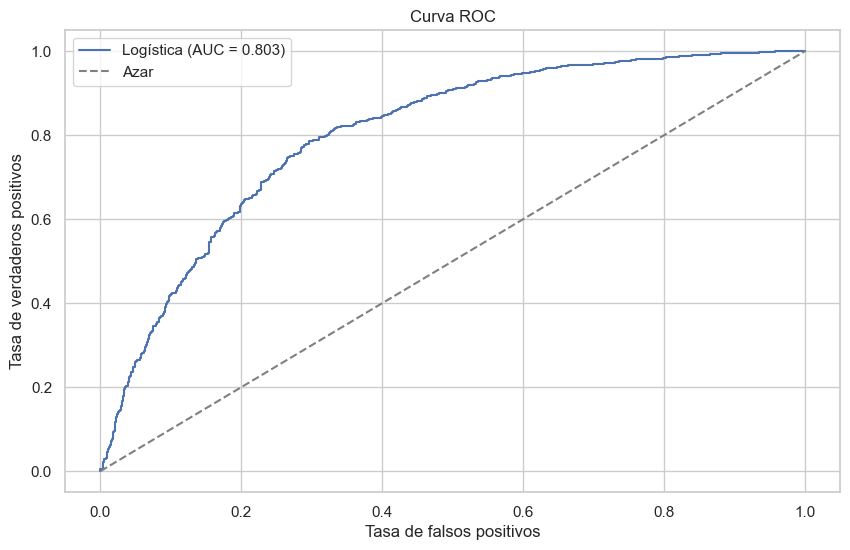

In [46]:
fpr, tpr, _ = roc_curve(y_te, proba)
plt.plot(fpr, tpr, label=f"Logística (AUC = {roc_auc_score(y_te, proba):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Azar")
plt.xlabel("Tasa de falsos positivos"); plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC")
plt.legend()
plt.show()

**Interpretación de la curva ROC**

En este gráfico podemos ver cómo cambia la capacidad del modelo para identificar correctamente a las personas con hipertensión diagnosticada cuando modificamos el umbral de clasificación.

La curva ROC representa dos medidas:

- **Eje horizontal (tasa de falsos positivos):** proporción de personas sin diagnóstico que el modelo clasifica incorrectamente como hipertensas.
- **Eje vertical (tasa de verdaderos positivos):** proporción de personas con diagnóstico que el modelo identifica correctamente. Es decir, el recall.

La línea diagonal discontinua representa el comportamiento de un clasificador sin capacidad de discriminación, equivalente al azar. Cuanto más se acerque nuestra curva a la esquina superior izquierda, mejor será el comportamiento del modelo.

En nuestro caso obtenemos un **AUC de 0,803**, lo que significa que, si escogemos al azar una persona con hipertensión diagnosticada y otra sin ella, el modelo asignará una probabilidad estimada mayor a la primera aproximadamente el 80,3 % de las veces.

Esto nos indica que el modelo tiene una capacidad bastante buena para ordenar a los participantes según su probabilidad estimada de pertenecer a la clase positiva.

Sin embargo, hay algo interesante: **aunque el AUC es relativamente bueno, el recall que obtenemos utilizando el umbral habitual de 0,5 es de solo 0,566**.

Esto ocurre porque ambas medidas evalúan cosas diferentes. El AUC tiene en cuenta distintos umbrales de clasificación, mientras que el recall que hemos calculado corresponde únicamente al umbral de 0,5.

Por tanto, podríamos estudiar otros umbrales para intentar identificar a más personas con diagnóstico de hipertensión. Eso sí, reducir el umbral normalmente también aumentaría los falsos positivos, por lo que tendríamos que buscar un equilibrio según el objetivo del modelo.

En definitiva, **la regresión logística consigue distinguir razonablemente bien entre los dos grupos, pero su clasificación con el umbral actual todavía tiene margen de mejora**, especialmente en la detección de los casos positivos.

### 6.4 (Opcional) Comparación con LDA

In [38]:
lda = LinearDiscriminantAnalysis().fit(sc_log.transform(X_tr), y_tr)
pred_lda = lda.predict(sc_log.transform(X_te))
proba_lda = lda.predict_proba(sc_log.transform(X_te))[:, 1]

print("LDA:")
print(f"  Accuracy: {accuracy_score(y_te, pred_lda):.3f}")
print(f"  AUC     : {roc_auc_score(y_te, proba_lda):.3f}")

LDA:
  Accuracy: 0.737
  AUC     : 0.803


Por último, hemos querido comparar nuestra regresión logística con otro modelo de clasificación: **LDA (Análisis Discriminante Lineal)**.

Aunque ambos modelos sirven para clasificar observaciones, funcionan de forma diferente. La regresión logística estima directamente la probabilidad de pertenecer a una clase, mientras que LDA estudia cómo se distribuyen las variables en cada grupo para encontrar una forma de separarlos.

Para realizar la comparación hemos utilizado los mismos conjuntos de entrenamiento y test, de manera que ambos modelos se evalúen sobre los mismos participantes.

Los resultados son prácticamente idénticos:

- **Regresión logística:** accuracy de 0,736 y AUC de 0,803.
- **LDA:** accuracy de 0,737 y AUC de 0,803.

Como vemos, LDA obtiene un porcentaje de aciertos ligeramente superior, pero la diferencia es de apenas 0,001. Además, ambos modelos tienen el mismo AUC al redondear a tres decimales.

Por tanto, **no encontramos una mejora relevante al utilizar LDA en lugar de regresión logística**. Los dos modelos consiguen una capacidad de clasificación muy parecida con los predictores que hemos seleccionado.

Esto también nos muestra que, aunque dos modelos funcionen de manera diferente, pueden terminar ofreciendo resultados prácticamente iguales cuando trabajan con los mismos datos.

En nuestro caso, nos quedaríamos con la regresión logística por la facilidad para interpretar sus coeficientes mediante los *odds ratios*, aunque los resultados obtenidos no permiten afirmar que uno de los dos modelos sea claramente mejor que el otro.

## 7. ¿Una o varias bases de datos?

Para realizar esta práctica hemos utilizado **un único conjunto de datos, NHANES**, ya que contiene suficientes variables y observaciones para aplicar todas las técnicas que nos pide el enunciado.

A partir de estos datos hemos podido plantear diferentes problemas:

- **Regresión lineal:** utilizando la presión arterial sistólica (`sbp`) como variable respuesta cuantitativa.
- **Ridge y Lasso:** trabajando con un conjunto más amplio de biomarcadores, algunos de ellos bastante correlacionados entre sí.
- **PCA:** utilizando esos mismos predictores cuantitativos para estudiar si podemos resumir su información mediante componentes principales.
- **Regresión logística:** utilizando el diagnóstico de hipertensión (`hypertension_dx`) como variable respuesta binaria.

Por tanto, no hemos necesitado recurrir a una segunda base de datos.

Eso sí, **no todos los modelos utilizan exactamente las mismas observaciones ni las mismas variables**. En cada apartado hemos seleccionado las columnas que necesitábamos y eliminado los registros incompletos correspondientes. Por eso, el número de participantes puede variar entre unos análisis y otros.

Además, para evaluar la capacidad predictiva de los modelos hemos utilizado conjuntos de entrenamiento y test, reservando este último para la evaluación final. Cuando ha sido necesario seleccionar parámetros, como α en Ridge y Lasso o el número de componentes de PCR y PLS, hemos utilizado validación cruzada sobre los datos de entrenamiento.

## 8. Conclusiones

Después de aplicar las distintas técnicas de aprendizaje estadístico a nuestro conjunto de datos de NHANES, podemos sacar varias conclusiones.

**Relaciones y variables relevantes.** La edad es una de las variables que más destaca a lo largo del análisis. En la regresión lineal encontramos que, por cada año adicional, la presión sistólica estimada aumenta aproximadamente 0,49 mmHg. El IMC también presenta una relación positiva, aunque menos marcada. Ambas variables vuelven a aparecer asociadas con el diagnóstico de hipertensión en la regresión logística.

**Comparación de modelos.** La regresión múltiple mejora ligeramente a la simple, pero la diferencia no es demasiado grande. Algo parecido ocurre con Ridge, Lasso y Elastic Net: Lasso obtiene el menor MSE en test (235,623), aunque los resultados de los cuatro modelos son prácticamente iguales. Además, Lasso conserva 42 de las 46 variables, por lo que la selección ha sido bastante limitada. Esto nos muestra que añadir más variables o aplicar regularización no garantiza necesariamente una mejora importante en las predicciones.

**Análisis mediante PCA.** Hemos comprobado que la variabilidad está bastante repartida entre nuestras variables, ya que necesitamos 20 componentes para conservar el 80 % de la varianza total. Aun así, PCA nos ha permitido identificar grupos de indicadores relacionados, especialmente variables del hemograma y del metabolismo. Además, PLS consigue un error de validación parecido al de PCR utilizando menos componentes (16 frente a 40).

**Clasificación de hipertensión.** La regresión logística obtiene un accuracy del 73,6 % y un AUC de 0,803, pero únicamente identifica al 56,6 % de los participantes con hipertensión diagnosticada. Por tanto, aunque consigue distinguir razonablemente bien entre ambos grupos, todavía presenta bastantes falsos negativos. La comparación con LDA tampoco muestra diferencias importantes.

**Limitaciones.** Hemos trabajado con casos completos, por lo que algunas observaciones se han descartado debido a los valores ausentes. Además, no hemos utilizado los pesos muestrales de NHANES, algunas mediciones pueden estar influidas por tratamientos médicos y los resultados obtenidos representan asociaciones, no relaciones causales. Por tanto, tampoco podemos extrapolar directamente nuestras conclusiones a toda la población estadounidense.

En definitiva, esta práctica nos ha permitido comprobar que **un modelo más complejo no siempre consigue mejores resultados**. Más allá de comparar métricas, también hemos aprendido la importancia de entender nuestros datos, justificar las decisiones que tomamos y reconocer las limitaciones de los modelos que utilizamos.